# **Mazais praktiskais darbs**

**Uzdevums:** 0/1 Knapsack Problem

**Algoritms:** Simulated Annealing

**Datu kopa:** Pisinger datu kopas:
* `knapPI_1_*_1000`
* `knapPI_2_*_1000`
* `knapPI_3_*_1000`

**Pielietojums reālā situācijā:** Spēlētājs spēlē RPG žanra videospēli, kur spēlētāja varonis spēj panest ierobežota smaguma lietas savā inventārā. Šajā videospēlē katrai lietai (zobenam, kaklarotai, ķiverei u.c.) ir noteikts smagums kilogramos un vērtība zelta monētās. Spēlētāja mērķis ir sakārtot varoņa inventāru tā, lai viņš spētu aiznest pēc iespējas vērtīgākas mantas vienā gājienā pie tirgotāja – tātad lai maksimizētu zelta monētu ieguvumu no savu mantu pārdošanas tirgotājam.

## 1. Bibliotēkas

In [1]:
import os
import random
import pandas as pd
import math
import time
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import Counter, defaultdict

random.seed(42)

## 2. Datu kopa

Tiek izmantotas Pisinger *large_scale* datu kopas, kas atrodas `dataset/` mapē. Tās ir lejupielādētas no GitHub repozitorija<sup>[1]</sup>, kas tās ieguva no Pisinger mājaslapas<sup>[2]</sup>, tomēr repozitorijs norāda, ka sākotnējie linki no šīs mājaslapas vairs nav pieejami.

Failu sadalījums: 3 tipi, 7 izmēri (`n = 100, 200, 500, 1000, 2000, 5000, 10000`), kopā 21 datu kopa.

Pisinger rakstā<sup>[3]</sup> ir aprakstīti vairāki datu kopu tipi, kas atšķiras ar to, kā priekšmeta vērtība `p` ir saistīta ar tā svaru `w`. Visās datu kopās vērtības un svari nepārsniedz `R = 1000` (tas ir norādīts arī faila nosaukumā, piem., `knapPI_1_500_1000_1`):
- `knapPI_1` – **nekorelētas** (*uncorrelated*): `p` un `w` ir nejauši intervālā `[1, R]`. Datos korelācija starp vērtību un svaru ir ≈ 0;<sup>[3]</sup> 
- `knapPI_2` – **vāji korelētas** (*weakly correlated*): `p` ir nejauša intervālā `[w − R/10, w + R/10]`, `p ≥ 1`. Datos `p − w` ir intervālā `[−100, 100]`, korelācija ≈ 0,98;<sup>[3]</sup> 
- `knapPI_3` – **stipri korelētas** (*strongly correlated*): `p = w + R/10`. Datos `p − w = 100` visiem priekšmetiem.<sup>[3]</sup> 

Katrai datu kopai ir 2 faili:
- `dataset/large_scale/<nosaukums>`:
    - pirmā rinda – `n` (priekšmetu skaits) un `c` (inventāra ietilpība);
    - nākamās `n` rindas – katra priekšmeta vērtība un svars;
    - pēdējā rinda – optimālais risinājums (`1`, ja priekšmets ir iekļauts optimālajā risinājumā, citādi `0`).
- `dataset/large_scale-optimum/<nosaukums>` – optimālā risinājuma vērtība `z`.

Mazāko datu kopu priekšmeti sakrīt ar lielāko datu kopu pirmajiem priekšmetiem, taču katrai datu kopai ir sava ietilpība `c` un optimālā vērtība `z`, tādēļ tās ir atsevišķas problēmas. Ielādējot tiek pārbaudīts, ka optimālā risinājuma vērtība sakrīt ar `z`.

3.–7. sadaļā tiek detalizēti apskatītas un notestētasdažādas datu kopas.

**Avoti:**
1. Daniel Freitas Martins (2024). *knapsack-01-instances* https://github.com/dnlfm/knapsack-01-instances/tree/main
2. Pisinger, D. *David Pisinger's optimization codes*  https://hjemmesider.diku.dk/~pisinger/codes.html
3. Pisinger, D. (2005). *Where are the hard knapsack problems?* https://www.dcs.gla.ac.uk/~pat/cpM/jchoco/knapsack/papers/hardInstances.pdf


In [2]:
# Funkcija, lai ielādētu Pisinger datu kopu (priekšmetu fails + optimālās vērtības fails)
def load_dataset(name: str) -> dict:
    with open(f'dataset/large_scale/{name}') as f:
        lines = [line.split() for line in f if line.strip()]
    n, capacity = map(int, lines[0])
    solution = list(map(int, lines[n + 1]))
    items = [{'id': i + 1, 'value': int(v), 'weight': int(w), 'optimal': solution[i]}
             for i, (v, w) in enumerate(lines[1:n + 1])]

    with open(f'dataset/large_scale-optimum/{name}') as f:
        optimal = int(f.read().split()[0])

    # Pārbaude, vai optimālā risinājuma vērtība sakrīt ar z
    assert sum(it['value'] for it in items if it['optimal']) == optimal, f'[WARNING] {name}: optimālais risinājums nesakrīt ar z'
    return {'n': n, 'capacity': capacity, 'optimal': optimal, 'items': items}


# Visas datu kopas: 3 tipi, 7 izmēri
SIZES = [100, 200, 500, 1000, 2000, 5000, 10000]
instances = {f'knapPI_{t}_{n}': load_dataset(f'knapPI_{t}_{n}_1000_1') for t in (1, 2, 3) for n in SIZES}

# Galvenās datu kopas (n = 500) detalizētai testēšanai
datasets = {f'knapPI_{t}': instances[f'knapPI_{t}_500'] for t in (1, 2, 3)}

# Datu kopu pārskats
overview_rows = []
for name, ds in instances.items():
    values = pd.Series([it['value'] for it in ds['items']])
    weights = pd.Series([it['weight'] for it in ds['items']])
    diff = values - weights
    overview_rows.append({
        'Dataset':           name,
        'Number of items':   ds['n'],
        'Weight limit':      ds['capacity'],
        'Total item weight': sum(it['weight'] for it in ds['items']),
        'Total item value':  sum(it['value'] for it in ds['items']),
        'Best known value':  ds['optimal'],
        'Value range':       f'[{values.min()}, {values.max()}]',
        'Value − weight':    f'[{diff.min()}, {diff.max()}]',
        'Correlation':       f'{values.corr(weights):.3f}',
    })

pd.DataFrame(overview_rows).style.hide(axis='index')


Dataset,Number of items,Weight limit,Total item weight,Total item value,Best known value,Value range,Value − weight,Correlation
knapPI_1_100,100,995,50378,50044,9147,"[7, 997]","[-891, 861]",-0.042
knapPI_1_200,200,1008,101828,99618,11238,"[3, 997]","[-891, 861]",0.083
knapPI_1_500,500,2543,256932,247071,28857,"[3, 998]","[-959, 928]",0.005
knapPI_1_1000,1000,5002,505290,486504,54503,"[1, 998]","[-963, 981]",0.024
knapPI_1_2000,2000,10011,1011130,977737,110625,"[1, 1000]","[-983, 981]",-0.003
knapPI_1_5000,5000,25016,2526647,2474772,276457,"[1, 1000]","[-984, 981]",-0.018
knapPI_1_10000,10000,49877,5037654,4979067,563647,"[1, 1000]","[-984, 981]",-0.018
knapPI_2_100,100,995,50378,51114,1514,"[1, 1040]","[-100, 99]",0.981
knapPI_2_200,200,1008,101828,103002,1634,"[1, 1071]","[-100, 99]",0.981
knapPI_2_500,500,2543,256932,258317,4566,"[1, 1074]","[-100, 100]",0.979


## 3. Priekšapstrāde

Esošā datu kopa ir parasti skaitļi, tiem nav īstas nozīmes. Lai datu kopu padarītu interesantāku un labāk atspoguļotu RPG problēmas situāciju, datu kopai tiek veikta priekšapstrāde:

- `value` – priekšmeta vērtība tiek saglabāta nemainīta un uzskatīta par zelta monētām (`gold`);
- `weight` – sākotnējā ietilpības vērtība `c` tiek dalīta ar `10`, lai iegūtu reālistisku pārnēsājamā svara ietilpību kilogramos. Piemēram, `2543 → 254,3 kg`;
- priekšmetam tiek piešķirts unikāls nosaukums (visinteresantākā daļa).

### Priekšmetu nosaukumu ģenerēšana

Katram priekšmetam no datu kopas algoritmiski tiek piešķirts nosaukums (piem., *Dwarven Mithril Sword of Frost*), ko ietekmē priekšmeta svara un vērtības, lai tie būtu ticami. Algoritms sastāv no 3 soļiem:

1. **Svars.** Katram priekšmeta tipam (`Ring`, `Potion`, `Sword`, `Plate Armor`, `Anvil` u.c.) ir noteikts reālistisks svara intervāls kilogramos. Priekšmetam var piešķirt tikai tādu kategoriju, kuras intervālā ietilpst tā svars. Ja derīgas ir vairākas kategorijas, tiek izvēlēta vismazāk izmantotā, lai kategorijas būtu vienmērīgāk sadalītas. Piemēri:
    - `gredzens 0,1–1 kg`;
    - `zobens 2,5–8 kg`;
    - `tronis 70–100 kg`.
2. **Retums.** Vienas kategorijas priekšmeti tiek sakārtoti pēc vērtības, un, atkarībā no to vietas šajā secībā, tiem tiek piešķirts retums. Dažās vieglajās kategorijās ir tikai 1–2 priekšmeti, un, ja vieta tiktu ņemta precīzi, dārgākais priekšmets katrā kategorijā vienmēr būtu `Legendary` (piem., `n = 500` datu kopās `Legendary` būtu 8% priekšmetu, nevis 3%). Tādēļ katra priekšmeta vieta tiek nobīdīta par nejaušu daļu no vienas pozīcijas (lai retumi visās kategorijās vidēji tiek sadalīti vienādās proporcijās).
Retums nozīmē, cik dārgs ir priekšmets salīdzinājumā ar līdzīgiem priekšmetiem, un vienas kategorijas ietvaros retāks priekšmets vienmēr ir vērtīgāks. Retums iedalās (sākot no lētākā):
    - 50% – `Common`;
    - 25% – `Uncommon`;
    - 15% – `Rare`;
    - 7% – `Epic`;
    - 3% – `Legendary`.
3. **Kategorijas grupa un retums → nosaukums.** Katra kategorija pieder materiālu grupai, un katrai grupai ir savi 3 materiāli katrai retuma pakāpei (piem., metālam `Iron → Steel → Silver → Mithril → Dragonbone`). Tas novērš neloģiskas kombinācijas, piemēram, "dzelzs dzira". Kategorijas iedalās:
    - `metal`;
    - `jewelry`;
    - `alchemy`;
    - `textile`;
    - `wood`;
    - `heavy`.

**Nosaukuma struktūra.** Nosaukuma sarežģītība ir atkarīga no priekšmeta retuma:
- `Common` – `materiāls + kategorija` (*Iron Axe*);
- `Uncommon` – `izcelsme + materiāls + kategorija` (*Orcish Steel Axe*);
- `Rare`, `Epic`, `Legendary` – `izcelsme + materiāls + kategorija + epitets` (*Dwarven Mithril Axe of Frost*, *Druidic Death Potion of Frost*).

Lielās datu kopās (līdz `n = 10000`) vienā kategorijā var būt simtiem `Common` un `Uncommon` priekšmetu, tādēļ, kad šie nosaukumi ir izsmelti, tiem tiek pievienota krāsa – `(krāsa)` (*Iron Axe (Blue)*). Kad izsmelti arī tie, krāsas vietā tiek pievienots stāvoklis – `(stāvoklis)` (*Iron Axe (Used)*), un tikai tad abi kopā – `(krāsa) (stāvoklis)` (*Iron Axe (Blue) (Polished)*). Priekšmetu krāsošana un stāvoklis ir bieži sastopami RPG spēļu elementi. Stāvokļi tiek piešķirti secībā no lētākā uz dārgāko: lētākie priekšmeti ir `Broken` vai `Used`, bet dārgākie – `Blessed` vai `Enchanted`.

Tātad no nosaukuma vien var nolasīt priekšmeta retumu: bez izcelsmes – `Common`, ar izcelsmi – `Uncommon`, ar epitetu – `Rare` vai augstāk. Katras kategorijas un retuma kombinācijas ietvaros lētākie priekšmeti saņem vienkāršākos nosaukumus (vispirms bez krāsas un stāvokļa), un katrs nosaukums tiek piešķirts tikai vienreiz, tāpēc datu kopas ietvaros visi nosaukumi ir unikāli (starp dažādām datu kopām nosaukumi var atkārtoties). Kategorijas tika ģenerētas un sakārtotas ar MI palīdzību.

Piezīme: Nosaukumi, kategorijas un retums neietekmē optimizācijas algoritmu, jo tas izmanto tikai svaru un vērtību. Tas ir tikai un vienīgi uzdevuma un rezultātu interesantākai interpretācijai. Tādēļ var uzdot jautājumu: **Vai visoptimālākais risinājums izmantos retākos priekšmetus?**

In [3]:
# Retuma pakāpes. Iedalītas pēc kumulatīvās daļas kategorijas ietvaros (value)
RARITIES = [('Common', 0.50), ('Uncommon', 0.75), ('Rare', 0.90), ('Epic', 0.97), ('Legendary', 1.00)]

# Materiālu grupas. Sastāv no materiāliem katrai retuma pakāpei un izcelsmes
GROUPS = {
    'metal': {
        'materials': [['Iron', 'Bronze', 'Copper'], ['Steel', 'Blacksteel', 'Cobalt'], ['Silver', 'Meteoric', 'Orichalcum'],
                      ['Mithril', 'Runesteel', 'Moonsteel'], ['Adamantite', 'Dragonbone', 'Celestial']],
        'origins':   ['Dwarven', 'Orcish', 'Elven', 'Nordic', "Knight's", 'Pirate', "Guard's", 'Mercenary'],
    },
    'jewelry': {
        'materials': [['Copper', 'Bone', 'Amber'], ['Silver', 'Pearl', 'Jade'], ['Gold', 'Amethyst', 'Topaz'],
                      ['Ruby', 'Emerald', 'Sapphire'], ['Diamond', 'Starmetal', 'Moonstone']],
        'origins':   ['Elven', "Queen's", 'Noble', "Wizard's", 'Dwarven', "Mermaid's", 'Priestly'],
    },
    'alchemy': {
        'materials': [['Healing', 'Mana', 'Stamina'], ['Strength', 'Swiftness', 'Resistance'],
                      ['Invisibility', 'Fire Breath', 'Water Breathing'], ['Dragon Blood', 'Time', 'Clairvoyance'],
                      ['Immortality', 'Death', 'Resurrection']],
        'origins':   ["Witch's", "Alchemist's", 'Druidic', "Shaman's", 'Holy', 'Swamp'],
    },
    'textile': {
        'materials': [['Linen', 'Leather', 'Wool'], ['Silk', 'Wolfskin', 'Velvet'], ['Bearskin', 'Shadowsilk', 'Wyvern Hide'],
                      ['Moonsilk', 'Griffin Hide', 'Spidersilk'], ['Phoenix Feather', 'Dragonhide', 'Starweave']],
        'origins':   ["Hunter's", "Wanderer's", "Thief's", "Knight's", 'Elven', 'Nordic', 'Nomad'],
    },
    'wood': {
        'materials': [['Pine', 'Birch', 'Spruce'], ['Oak', 'Ash', 'Maple'], ['Yew', 'Ebony', 'Ironwood'],
                      ['Ghostwood', 'Elderwood', 'Bloodwood'], ['Worldtree', 'Thunderwood', 'Dreamwood']],
        'origins':   ["Hunter's", 'Elven', 'Druidic', "Ranger's", 'Bandit', 'Village'],
    },
    'heavy': {
        'materials': [['Stone', 'Wooden', 'Iron'], ['Bronze', 'Granite', 'Sandstone'], ['Marble', 'Silver', 'Jade'],
                      ['Gold', 'Obsidian', 'Crystal'], ['Dragonbone', 'Living Stone', 'Starmetal']],
        'origins':   ['Dwarven', 'Royal', 'Pirate', 'Temple', "Merchant's", "Giant's", "Miner's"],
    },
}

# Krāsas. Priekšmetiem ar retumu 'Common' un 'Uncommon'
COLOURS = ['Brown', 'Grey', 'Beige', 'Orange', 'Yellow', 'Green', 'Red', 'White', 'Cyan', 'Blue', 'Teal', 'Pink', 'Black', 'Purple', 'Magenta']
# Stāvokļi. 'Common' un 'Uncommon' priekšmetiem, kad izsmelti nosaukumi ar krāsu (secībā no lētākā uz dārgāko)
CONDITIONS = ['Broken', 'Damaged', 'Used', 'Worn', 'Old', 'Restored', 'Polished', 'Pristine', 'Blessed', 'Enchanted']

# Epiteti. Visiem priekšmetiem no pakāpes 'Rare' un augstāk
EPITHETS = ['of Flame', 'of Frost', 'of Thunder', 'of Shadows', 'of Light', 'of the Night', 'of Storms', 'of Blood', 'of the Moon', 'of the Sun']

# Kategorijas: (nosaukums, grupa, min_kg, max_kg)
CATEGORIES = [
    ('Ring',         'jewelry',  0.1,   1.0),
    ('Amulet',       'jewelry',  0.2,   2.0),
    ('Necklace',     'jewelry',  0.3,   3.0),
    ('Potion',       'alchemy',  0.2,   2.5),
    ('Elixir',       'alchemy',  0.5,   4.0),
    ('Dagger',       'metal',    0.5,   3.0),
    ('Gloves',       'textile',  0.5,   3.0),
    ('Boots',        'textile',  1.5,   5.0),
    ('Cloak',        'textile',  1.5,   6.0),
    ('Crown',        'jewelry',  2.0,   5.0),
    ('Helmet',       'metal',    2.0,   7.0),
    ('Sword',        'metal',    2.5,   8.0),
    ('Axe',          'metal',    3.0,  10.0),
    ('Bow',          'wood',     1.0,   4.0),
    ('Staff',        'wood',     2.0,   6.0),
    ('Shield',       'metal',    5.0,  15.0),
    ('Warhammer',    'metal',    8.0,  20.0),
    ('Greatsword',   'metal',    8.0,  25.0),
    ('Crossbow',     'wood',     8.0,  16.0),
    ('Chainmail',    'metal',   10.0,  25.0),
    ('Plate Armor',  'metal',   20.0,  40.0),
    ('Tower Shield', 'metal',   15.0,  30.0),
    ('Statue',       'heavy',   20.0, 100.0),
    ('Chest',        'wood',    30.0,  80.0),
    ('Anvil',        'metal',   40.0, 100.0),
    ('Barrel',       'wood',    25.0, 100.0),
    ('Geteld',       'textile', 20.0,  70.0),
    ('Horse Armor',  'metal',   35.0,  70.0),
    ('Totem',        'heavy',   25.0,  80.0),
    ('Sarcophagus',  'heavy',   50.0, 100.0),
    ('Obelisk',      'heavy',   60.0, 100.0),
    ('Altar',        'heavy',   50.0, 100.0),
    ('Throne',       'heavy',   70.0, 100.0),
    ('Cauldron',     'metal',   70.0, 100.0),
    ('Cannon',       'metal',   80.0, 100.0),
]


# Funkcija, lai ģenerētu iespējamos priekšmetu nosaukumus atkarībā no kategorijas, grupas un retuma pakāpes
def candidate_names(category: str, group: str, tier: int) -> list:
    g = GROUPS[group]
    mats = g['materials'][tier]
    base = lambda o, m: f'{o} {m} {category}'.strip()

    # Nosaukumi bez iekavām, pēc tam ar krāsu, pēc tam ar stāvokli, pēc tam ar krāsu un stāvokli
    # (katrs stāvoklis ir atsevišķs līmenis, lai stāvokļi tiktu piešķirti secībā no lētākā uz dārgāko)
    def with_extras(names: list) -> list:
        return [names,
                [f'{n} ({c})' for c in COLOURS for n in names],
                *[[f'{n} ({s})' for n in names] for s in CONDITIONS],
                *[[f'{n} ({c}) ({s})' for c in COLOURS for n in names] for s in CONDITIONS]]

    # Common: materiāls + kategorija
    if tier == 0:
        return with_extras([base('', m) for m in mats])

    # Uncommon: izcelsme + materiāls + kategorija
    with_origin = [base(o, m) for o in g['origins'] for m in mats]
    if tier == 1:
        return with_extras(with_origin)

    # Rare, Epic, Legendary: izcelsme + materiāls + kategorija + epitets
    return [[f'{n} {e}' for e in EPITHETS for n in with_origin]]


# Funkcija, lai piešķirtu katram priekšmetam kategoriju, retumu un unikālu nosaukumu
def name_items(items: list, seed: int = 42) -> list:
    rng = random.Random(seed)

    # 1) Kategorija pēc svara (no derīgajām kategorijām izvēlas vismazāk izmantoto)
    usage = Counter()
    by_cat = defaultdict(list)
    for it in sorted(items, key=lambda it: it['weight']):
        kg = it['weight'] / 10
        eligible = [c for c in CATEGORIES if c[2] <= kg <= c[3]]
        rng.shuffle(eligible)
        cat = min(eligible, key=lambda c: usage[c[0]])
        usage[cat[0]] += 1
        it['category'], it['group'] = cat[0], cat[1]
        by_cat[cat[0]].append(it)

    for cat, its in by_cat.items():
        # 2) Retums pēc vērtības (value) ranga kategorijas ietvaros. Vieta tiek nobīdīta par nejaušu daļu (0–1),
        #    lai arī mazās kategorijās retumi būtu vidēji sadalīti tādās pašās proporcijās kā lielās
        its.sort(key=lambda it: it['value'])
        tiers = defaultdict(list)
        for r, it in enumerate(its):
            q = (r + rng.random()) / len(its)
            tier = next(t for t, (_, lim) in enumerate(RARITIES) if q <= lim)
            it['rarity'] = RARITIES[tier][0]
            tiers[tier].append(it)

        # 3) Unikāls nosaukums, lētākie priekšmeti saņem vienkāršākos nosaukumus (vispirms bez krāsas un stāvokļa)
        for tier, tier_items in tiers.items():
            pool = []
            for level in candidate_names(cat, its[0]['group'], tier):
                rng.shuffle(level)
                pool += level
            assert len(pool) >= len(tier_items), f'[WARNING] Nepietiek nosaukumu: {cat}, {RARITIES[tier][0]}'
            for it, name in zip(tier_items, pool):
                it['name'] = name
    return items


# Piešķir nosaukumus visiem priekšmetiem katrā datu kopā (visi izmēri)
for ds in instances.values():
    name_items(ds['items'])
    names = [it['name'] for it in ds['items']]
    assert len(set(names)) == len(names), '[WARNING] Nosaukumi nav unikāli'


# Piemērs: 5 nejauši priekšmeti no katras datu kopas
sample_rows = []
for name, ds in datasets.items():
    for it in random.Random(42).sample(ds['items'], 5):
        sample_rows.append({
            'Dataset':     name,
            'Name':        it['name'],
            'Category':    it['category'],
            'Rarity':      it['rarity'],
            'Weight (kg)': f"{it['weight'] / 10:.1f}",
            'Value':       f"{it['value']} gold",
        })

pd.DataFrame(sample_rows).style.hide(axis='index')

Dataset,Name,Category,Rarity,Weight (kg),Value
knapPI_1,Stone Throne (Orange),Throne,Common,77.6,103 gold
knapPI_1,Giant's Crystal Throne of the Moon,Throne,Epic,72.4,824 gold
knapPI_1,Knight's Runesteel Warhammer of the Night,Warhammer,Epic,12.2,667 gold
knapPI_1,Wizard's Silver Crown,Crown,Uncommon,2.6,954 gold
knapPI_1,Nordic Moonsteel Cauldron of Light,Cauldron,Epic,78.5,930 gold
knapPI_2,Temple Bronze Throne,Throne,Uncommon,77.6,804 gold
knapPI_2,Merchant's Sandstone Throne,Throne,Uncommon,72.4,775 gold
knapPI_2,Bronze Warhammer,Warhammer,Common,12.2,40 gold
knapPI_2,Amber Crown,Crown,Common,2.6,38 gold
knapPI_2,Nordic Blacksteel Cauldron,Cauldron,Uncommon,78.5,857 gold


## 4. Problēmas reprezentācija

Lai optimizācijas algoritms varētu risināt varoņa inventāra problēmu, šī problēma ir jāpārveido formā, ar kuru algoritms var strādāt. Tātad jānosaka, kas ir risinājums (domēns), kā vērtēt risinājumu (novērtēšana) un kā no viena risinājuma pāriet uz citu (gājiens).

### a) Domēns

Sekojot Pisinger<sup>[1]</sup> formulējumam, 0/1 Knapsack Problem var uzrakstīt kā veselu skaitļu programmēšanas modeli:

$$
\begin{aligned}
\text{(KP)} \quad \text{maximize} \quad & \sum_{j=1}^{n} p_j x_j & (1) \
\text{subject to} \quad & \sum_{j=1}^{n} w_j x_j \le c & (2) \
& x_j \in \{0, 1\}, \quad j = 1, \dots, n & (3)
\end{aligned}
$$

kur:
- $n$ – priekšmetu skaits datu kopā (katrā kopā $n = 500$);
- $p_j$ – priekšmeta $j$ cena zelta monētās (kodā `value`);
- $w_j$ – priekšmeta $j$ svars (kodā `weight`);
- $c$ – inventāra lielums jeb lielākais svars, ko varonis spēj panest (kodā `capacity`);
- $x_j$ – lēmums, vai priekšmets $j$ tiek ņemts līdzi.

Visus $n$ lēmumus kopā apzīmē ar x = $(x_1, x_2, \dots, x_n)$

Tātad risinājums ir binārs saraksts `x` ar garumu $n$ (nosacījums (3)):
- `x[j] = 1` – priekšmets $j$ ir ielikts varoņa inventārā un tiks aiznests pārdot tirgotājam;
- `x[j] = 0` – priekšmets netiek ielikts varoņa inventārā.

Risinājums ir derīgs tikai tad, ja varoņa inventāra kopējais svars nepārsniedz inventāra lielumu `capacity` (nosacījums (2)).

### b) Novērtēšana

Mērķa funkcija ir varoņa inventāra sakārtojuma kopējā augstākā vērtība zelta monētās, kas nepārsniedz inventāra lielumu. Ja tas tiek pārsniegts (nav izpildīts nosacījums (2)), varonis to nespēj panest, tādēļ šāds risinājums nav derīgs un tā vērtība tiek uzskatīta par `0`.

Algoritma darbības laikā varoņa inventāra svars un vērtība netiek pārrēķināti no jauna katrā solī, bet tiek atjaunināti pakāpeniski – pieskaitot vai atņemot tikai tos priekšmetus, kas tika ielikti vai izņemti. Tas algoritmu ievērojami paātrina, jo katrā solī nav jāsaskaita visi 500 priekšmeti. Pilnā novērtēšanas funkcija `evaluate` tiek izmantota algoritma beigās, lai pārbaudītu, ka atrastais varoņa inventāra sakārtojums tiešām ir derīgs.

### c) Gājiens

Simulated Annealing algoritms nosaka tikai to, vai jauno (kaimiņu) risinājumu pieņemt. Kā šo kaimiņu iegūt ir jāizvēlas atsevišķi, atbilstoši risināmajai problēmai. Gājiena kaimiņa inventāra sakārtojumam ir jābūt līdzīgam esošajam. Ja katrs gājiens radītu pilnīgi citu inventāra sakārtojumu, algoritms kļūtu par nejaušu minēšanu. Ja kaimiņu risinājums pārsniedz inventāra lielumu, tas tiek uzskatīts par nederīgu, un algoritms parasti to noraida. Galu galā, ar šiem gājieniem ir jānonāk pie optimāla risinājuma.

Kodā gājiens no esošā varoņa inventāra sakārtojuma sadalās 3 soļos:
1. **Izmaiņa.** Tiek izvēlēts nejaušs priekšmets. Ja tas jau ir inventārā, varonis to izņem, ja nav – ieliek.
2. **Pārsvara labošana.** Ja pēc ielikšanas varoņa inventāra smaguma limits ir pārsniegts, no tā tiek izņemti priekšmeti ar vismazāko zelta uz kg attiecību (vismazāk izdevīgie), līdz inventāra svars atkal nepārsniedz limitu.
3. **Brīvās vietas aizpildīšana.** Atbrīvotajā vietā nejaušā secībā tiek ielikti priekšmeti, kas vēl ietilpst inventārā.

Es sākotnēji izmantoju tikai 1 soli, kas ir viena nejauša priekšmeta ielikšana vai izņemšana. Testējot kodu, ar šādu gājienu 90–94% kaimiņu inventāru bija par smagiem (skat. 7.3. sadaļu). Sākotnējais inventārs jau ir gandrīz pilns, tādēļ gandrīz jebkura jauna priekšmeta ielikšana pārsniedz limitu. Algoritms šos inventāru sakārtojumus noraidīja un praktiski nekad neuzlaboja sākuma risinājumu, t.i., netika izpildīta derīguma prasība. Tādēļ tika pievienoti citi soļi, un galu galā gājieni iedalījās šādi:
- **1. solis** ir viena nejauša priekšmeta ielikšana vai izņemšana.
- **2. solis** nodrošina derīgumu. Tiek izņemti vismazāk izdevīgie priekšmeti, nevis nejauši, lai labošana zaudētu pēc iespējas mazāk zelta uz katru atbrīvoto kilogramu.
- **3. solis** neļauj inventāram palikt pustukšam, jo neizmantota vieta ir zaudēts zelts. Priekšmeti tiek likti nejaušā secībā, nevis pēc zelta uz kg attiecības – citādi katrs gājiens ieliktu tos pašus priekšmetus un inventārs ātri atgrieztos pie sākuma risinājuma. Nejaušība ļauj izmēģināt dažādas kombinācijas.

Kopumā gājiens joprojām ir neliela izmaiņa (viens priekšmets un daži, kas jāizņem vai jāieliek tā dēļ), tādēļ visas trīs prasības ir izpildītas. Arī spēlētājs rīkotos līdzīgi – lai ieliktu inventārā jaunu priekšmetu, viņš atbrīvo vietu, atsakoties no priekšmetiem, kas dod vismazāk zelta uz kilogramu, un tad brīvo vietu aizpilda ar to, kas vēl ietilpst.

**Sākuma risinājums.** Algoritms sāk no alkatīgā (greedy) risinājuma. Priekšmeti tiek sakārtoti pēc zelta uz kg attiecības un likti inventārā pēc kārtas. Ja priekšmets neietilpst, tas tiek izlaists un tiek mēģināts nākamais. Tā rīkotos spēlētājs, kurš vienkārši vispirms ņem "izdevīgākās" lietas. Šis risinājums parasti var būt tuvs optimālajam, tomēr SA algoritma uzdevums ir to uzlabot. Turpmāk alkatīgais risinājums tiek izmantots arī kā salīdzinājuma bāze, lai novērtētu, cik daudz SA to uzlabo.

**Avots:**
1. Pisinger, D (2005). *Where are the hard knapsack problems?* https://www.dcs.gla.ac.uk/~pat/cpM/jchoco/knapsack/papers/hardInstances.pdf

In [4]:
# Funkcija, lai aprēķinātu inventārā ielikto priekšmetu kopējo svaru
def total_weight(solution: list, items: list) -> int:
    return sum(items[i]['weight'] for i in range(len(solution)) if solution[i])


# Funkcija, lai aprēķinātu inventārā ielikto priekšmetu kopējo vērtību (zeltu)
def total_value(solution: list, items: list) -> int:
    return sum(items[i]['value'] for i in range(len(solution)) if solution[i])


# Funkcija, lai aprēķinātu inventāra vērtību, ja varonis to spēj panest, citādi 0
def evaluate(solution: list, items: list, capacity: int) -> int:
    if total_weight(solution, items) > capacity:
        return 0
    return total_value(solution, items)


# Funkcija, lai ģenerētu sākuma risinājumu (greedy), kur priekšmetus liek inventārā pēc zelta uz kg attiecības (dilstoši), kamēr tie ietilpst
def initial_solution(items: list, capacity: int) -> list:
    order = sorted(range(len(items)), key=lambda i: items[i]['value'] / items[i]['weight'], reverse=True)
    solution = [0] * len(items)
    remaining = capacity
    for i in order:
        if items[i]['weight'] <= remaining:
            solution[i] = 1
            remaining -= items[i]['weight']
    return solution


# Funkcija, lai ģenerētu kaimiņu risinājumu (gājienu), kas izmaina inventāru x uz kaimiņu risinājumu 
# (x tiek mainīts uzreiz, atgriež jauno svaru, vērtību un mainītos priekšmetus)
#   by_ratio – priekšmetu indeksi, sakārtoti pēc zelta uz kg attiecības (augoši, vismazāk izdevīgie pirmie)
#   by_weight – priekšmetu indeksi, sakārtoti pēc svara (augoši, vieglākie pirmie)
def neighbour(x: list, weight: int, value: int, items: list, capacity: int,
              by_ratio: list, by_weight: list) -> tuple:
    changed = []

    # 1) Nejauši izvēlēts priekšmets tiek izņemts no inventāra vai ielikts tajā
    idx = random.randrange(len(items))
    x[idx] ^= 1
    changed.append(idx)
    if x[idx]:
        weight += items[idx]['weight']
        value += items[idx]['value']
    else:
        weight -= items[idx]['weight']
        value -= items[idx]['value']

    # 2) Ja inventārs ir par smagu, izņem vismazāk izdevīgos priekšmetus, līdz varonis to atkal spēj panest
    if weight > capacity:
        for i in by_ratio:
            if weight <= capacity:
                break
            if x[i] and i != idx:
                x[i] = 0
                changed.append(i)
                weight -= items[i]['weight']
                value -= items[i]['value']

    # 3) Brīvo vietu nejaušā secībā aizpilda ar priekšmetiem, kas vēl ietilpst inventārā (apskata tikai pietiekami vieglos)
    free = capacity - weight
    fits = []
    for i in by_weight:
        if items[i]['weight'] > free:
            break
        if not x[i] and i != idx:
            fits.append(i)
    random.shuffle(fits)
    for i in fits:
        if weight + items[i]['weight'] <= capacity:
            x[i] = 1
            changed.append(i)
            weight += items[i]['weight']
            value += items[i]['value']

    return weight, value, changed

**Gājiena piemērs.** Zemāk ir parādīts viens gājiens soli pa solim `knapPI_1` (`n = 500`) datu kopā, sākot no alkatīgā inventāra. No pirmajām 1000 nejaušības sēklām (`seed`) tiek izvēlēts gājiens, kurā notiek visi 3 soļi un inventāra vērtība samazinās vismazāk. Piemērs izmanto inventāra kopiju un pēc tam atjauno nejaušības stāvokli, tādēļ tas neietekmē pārējos rezultātus.

In [23]:
# Funkcija, lai parādītu vienu gājienu soli pa solim (no alkatīgā inventāra knapPI_1 datu kopā, n = 500)
def show_move_example(ds: dict, max_seed: int = 1000) -> None:
    items, capacity = ds['items'], ds['capacity']
    by_ratio = sorted(range(len(items)), key=lambda i: items[i]['value'] / items[i]['weight'])
    by_weight = sorted(range(len(items)), key=lambda i: items[i]['weight'])
    start = initial_solution(items, capacity)
    start_w, start_v = total_weight(start, items), total_value(start, items)

    # Priekšmeta apraksts. Nosaukums, retums, svars, vērtība un zelts uz kg
    def describe(i: int) -> str:
        it = items[i]
        kg = it['weight'] / 10
        return f'"{it["name"]}" ({it["rarity"]} | {kg:.1f} kg | {it["value"]} gold | {it["value"] / kg:.0f} gold/kg)'

    # Nejaušības stāvoklis tiek saglabāts un atjaunots, lai piemērs neietekmētu pārējo notebook
    saved_state = random.getstate()
    # No pirmajām max_seed sēklām izvēlas gājienu, kurā notiek visi 3 soļi un vērtība samazinās vismazāk
    best = None
    for seed in range(max_seed):
        random.seed(seed)
        x = start[:]
        new_w, new_v, changed = neighbour(x, start_w, start_v, items, capacity, by_ratio, by_weight)
        flipped = changed[0]
        removed = [i for i in changed[1:] if not x[i]]
        added = [i for i in changed[1:] if x[i]]
        if x[flipped] and removed and added and (best is None or new_v > best[1]):
            best = (new_w, new_v, x, flipped, removed, added)
    random.setstate(saved_state)
    new_w, new_v, x, flipped, removed, added = best

    # Svars pēc katra soļa
    w_after_change = start_w + items[flipped]['weight']
    w_after_repair = w_after_change - sum(items[i]['weight'] for i in removed)
    cap_kg = capacity / 10

    print(f'Sākuma inventārs (alkatīgais risinājums): {sum(start)} priekšmeti | '
          f'{start_w / 10:.1f} / {cap_kg:.1f} kg | {start_v} gold')
    print()
    print('1. Izmaiņa – nejauši izvēlēts priekšmets, kura nav inventārā, tiek ielikts:')
    print(f'   + {describe(flipped)}')
    print(f'   → {w_after_change / 10:.1f} / {cap_kg:.1f} kg – inventārs ir par smagu!')
    print()
    print('2. Labošana – tiek izņemti priekšmeti ar vismazāko zelta uz kg attiecību, līdz inventārs atkal ietilpst:')
    for i in removed:
        print(f'   − {describe(i)}')
    print(f'   → {w_after_repair / 10:.1f} / {cap_kg:.1f} kg | brīvā vieta {(capacity - w_after_repair) / 10:.1f} kg')
    print()
    print('3. Aizpildīšana – brīvajā vietā nejaušā secībā tiek ielikti priekšmeti, kas vēl ietilpst:')
    for i in added:
        print(f'   + {describe(i)}')
    print(f'   → {new_w / 10:.1f} / {cap_kg:.1f} kg')

show_move_example(datasets['knapPI_1'])

Sākuma inventārs (alkatīgais risinājums): 43 priekšmeti | 252.8 / 254.3 kg | 28834 gold

1. Izmaiņa – nejauši izvēlēts priekšmets, kura nav inventārā, tiek ielikts:
   + "Bronze Helmet" (Common | 6.0 kg | 291 gold | 48 gold/kg)
   → 258.8 / 254.3 kg – inventārs ir par smagu!

2. Labošana – tiek izņemti priekšmeti ar vismazāko zelta uz kg attiecību, līdz inventārs atkal ietilpst:
   − "Orcish Dragonbone Tower Shield of Flame" (Legendary | 18.1 kg | 998 gold | 55 gold/kg)
   → 240.7 / 254.3 kg | brīvā vieta 13.6 kg

3. Aizpildīšana – brīvajā vietā nejaušā secībā tiek ielikti priekšmeti, kas vēl ietilpst:
   + "Knight's Runesteel Warhammer of the Night" (Epic | 12.2 kg | 667 gold | 55 gold/kg)
   → 252.9 / 254.3 kg


## 5. Simulated Annealing algoritms

### d) Algoritms

Simulated Annealing (SA) ir radies no metālapstrādes analoģijas, kur materiālu sakarsē un pakāpeniski atdzesē, lai tas nonāktu stabilā stāvoklī.<sup>[1]</sup> Algoritmā šo lomu spēlē temperatūra `T`, kas nosaka varbūtību pieņemt sliktāku risinājumu. Augstā temperatūrā algoritms biežāk pieņem sliktākus risinājumus un vairāk izpēta iespējamos inventāra sadalījumus, bet, temperatūrai krītot, tas kļūst izvēlīgāks un pakāpeniski uzlabo esošo risinājumu. Sliktāku risinājumu pieņemšana ļauj izkļūt no "lokālā optimuma" – somas (manā uzdevumā saukts par varoņa inventāru), kuru nevar uzlabot ar vienu gājienu, bet kas nav labākā iespējamā.<sup>[1]</sup>

Algoritma soļi<sup>[1]</sup>:
1. Sāk ar sākuma risinājumu un augstu temperatūru `T = T_start`. Sākuma risinājumu var ģenerēt nejauši vai izveidot, izmantojot zināšanas par problēmu<sup>[2]</sup> – šeit tiek izmantots alkatīgais risinājums (skat. 4. sadaļu).
2. Ar gājienu izveido kaimiņu somu un aprēķina vērtības izmaiņu `Δ = f(kaimiņš) − f(esošā)`.
3. Ja `Δ ≥ 0`, kaimiņu pieņem vienmēr. Ja `Δ < 0`, to pieņem ar varbūtību `exp(Δ / T)`, citādi paliek esošā soma.
4. Atceras vērtīgāko līdz šim atrasto somu, jo esošā soma var kļūt sliktāka.
5. Atdzesē temperatūru: `T ← T · α`.
6. Apstājas, kad `T < T_min` vai sasniegts iterāciju limits `max_iter`.

Avotos pieņemšanas varbūtība ir rakstīta kā `exp(−Δ / T)`, jo tajos tiek minimizētas izmaksas un `Δ` ir izmaksu pieaugums. Šeit somas vērtība tiek maksimizēta, tādēļ zīme ir pretēja – sliktāka soma ir tad, ja `Δ < 0`.

Avotos nav vienotu parametru vērtību (piemēram, sākuma temperatūra 1 vai 100, `α = 0,95`)<sup>[2, 3]</sup>. Algoritma darbība ir atkarīga no sākuma temperatūras, dzesēšanas ātruma un apstāšanās nosacījuma, un tie jāizvēlas atbilstoši problēmai un pieejamajam skaitļošanas laikam. Lēna dzesēšana ļauj vairāk izpētīt, bet prasa vairāk iterāciju.<sup>[1]</sup>

Parametru nozīmi var aprēķināt no pieņemšanas varbūtības un temperatūras pēc $k$ iterācijām:

$$P = e^{\Delta / T}, \qquad T_k = T_{start} \cdot \alpha^k$$

Izmantotie parametri:
- **`T_min = 0.1`.** Zelta vērtības ir veseli skaitļi, tātad mazākais iespējamais zaudējums vienā gājienā ir 1 zelta monēta. Lai algoritma beigās netiktu pieņemts pat šāds zaudējums, `T_min` jābūt mazākam par 1. Tādēļ tika izvēlēts 0.1.
- **`T_start` un `α`** netiek izvēlēti iepriekš, bet tiek salīdzināti 6. sadaļā: $T_{start} \in \{5, 10, 50, 100, 500\}$ (no zemas līdz augstai sākuma temperatūrai) un $\alpha \in \{0{,}999;\ 0{,}9993;\ 0{,}9995;\ 0{,}9997;\ 0{,}9999\}$ (no ātras līdz lēnai dzesēšanai). Kopā tie nosaka iterāciju skaitu līdz `T_min`: $k = \ln(T_{min} / T_{start}) / \ln \alpha$, t.i., no ~3 900 ($T_{start} = 5$, $\alpha = 0{,}999$) līdz ~85 000 ($T_{start} = 500$, $\alpha = 0{,}9999$).
- **`max_iter = 100 000`** – stingra robeža iterāciju skaitam.
- **`move = neighbour`** – gājiena funkcija (4. sadaļas c) punkts). Parametrs ļauj salīdzināt dažādus gājienus (skat. 7.3. sadaļu).

**Avoti:**
1. GeeksforGeeks. *What is Simulated Annealing?* https://www.geeksforgeeks.org/artificial-intelligence/what-is-simulated-annealing/
2. GeeksforGeeks. *Simulated Annealing.* https://www.geeksforgeeks.org/dsa/simulated-annealing/
3. GeeksforGeeks. *Implement Simulated Annealing in Python.* https://www.geeksforgeeks.org/dsa/implement-simulated-annealing-in-python/


In [5]:
# Funkcija SA algoritmam 0/1 mugursomas problēmai
def simulated_annealing(
    items: list,
    capacity: int,
    T_start: float,
    alpha: float,
    T_min: float = 0.1,
    max_iter: int = 100_000,
    track_history: bool = False,
    move=neighbour,
) -> dict:
    # Priekšmetu secības, ko izmanto gājiens (efektivitātei aprēķinātas vienreiz, nevis katrā iterācijā)
    by_ratio = sorted(range(len(items)), key=lambda i: items[i]['value'] / items[i]['weight'])
    by_weight = sorted(range(len(items)), key=lambda i: items[i]['weight'])

    # Sākuma inventāra sadalījums ar alkatīgo (greedy) risinājumu
    current = initial_solution(items, capacity)
    current_w = total_weight(current, items)
    current_v = total_value(current, items)
    best, best_v = current[:], current_v

    T = T_start
    history = []
    t0 = time.perf_counter()

    for it in range(max_iter):
        if T < T_min:
            break

        # Kaimiņu inventārs un tā vērtības izmaiņa
        nb_w, nb_v, changed = move(current, current_w, current_v, items, capacity, by_ratio, by_weight)
        delta = nb_v - current_v

        # Labāku inventāru pieņem vienmēr, sliktāku – ar varbūtību exp(Δ/T), citādi gājiens tiek atcelts
        if delta >= 0 or random.random() < math.exp(delta / T):
            current_w, current_v = nb_w, nb_v
        else:
            for i in changed:
                current[i] ^= 1

        # Atceras vērtīgāko līdz šim atrasto inventāru
        if current_v > best_v:
            best, best_v = current[:], current_v

        # Temperatūras atdzesēšana
        T *= alpha

        # Vēsture grafikam (9. sadaļa): esošā un labākā vērtība ik pēc 100 iterācijām
        if track_history and it % 100 == 0:
            history.append((it, current_v, best_v))

    elapsed = time.perf_counter() - t0

    # Pārbaude, vai labākais inventārs nepārsniedz ietilpību un tā vērtība sakrīt ar pilno novērtēšanas funkciju
    assert evaluate(best, items, capacity) == best_v, '[WARNING] Atrastais inventāra sadalījums nav derīgs'

    return {
        'best_solution': best,
        'best_value': best_v,
        'elapsed': elapsed,
        'iterations': it + 1,
        'history': history,
    }

## 6. Parametru izvēle

Šajā sadaļā tiek salīdzinātas dažādas `T_start` un `α` vērtības. Visas 25 parametru kombinācijas (5 × 5) tiek pārbaudītas uz visām 21 datu kopām ar vienādu konfigurāciju:

| Parametrs | Vērtības |
|-----------|----------|
| `T_start` | 5, 10, 50, 100, 500 |
| `α` | 0,999; 0,9993; 0,9995; 0,9997; 0,9999 |
| Koda palaišanas reizes (`RUNS`) | 5 (sēklas `0–4`) |

SA algoritmu ietekmē izvēlētā sēkla (`seed`), tādēļ katrā palaišanas reizē tas var atrast citu risinājumu. Šī iemesla dēļ katra kombinācija uz katras datu kopas tiek palaista vairākas reizes ar sēklām `0, 1, …`, lai rezultātus varētu atkārtot. Kopā tās ir 2625 palaišanas (25 kombinācijas × 21 datu kopa × 5 reizes), kas aizņem aptuveni 2,5 stundas, no kurām vairāk nekā pusi (~82 min) – `n = 10000` datu kopas.

Rezultātu tabulu kolonnas:
- `Iterations` – iterāciju skaits līdz `T_min` (atkarīgs tikai no `T_start` un `α`);
- `n=… gap (%)` – vidējā atšķirība no labākā zināmā risinājuma šī izmēra datu kopās (vidēji pa 3 tipiem);
- `Mean gap (%)` – vidējā atšķirība visās datu kopās (katrai datu kopai ir vienāds svars);
- `Optimum found` – cik koda palaišanas reizēs tika atrasts labākais zināmais risinājums;
- `Avg time (s)` – vidējais vienas palaišanas izpildes laiks.

Pēc katras datu kopas rezultāti tiek saglabāti failā `results/param_runs.csv`. `n = 500` datu kopām tiek saglabāts arī pats risinājums (kuri priekšmeti ir somā), jo tas ir vajadzīgs detalizētai analīzei 7. sadaļā. Pārējām datu kopām risinājumi netiek saglabāti, lai fails nebūtu pārāk liels. Tas ļauj eksperimentu pārtraukt un turpināt vēlāk, jo jau aprēķinātās datu kopas var tikt ielādētas no faila, nevis aprēķinātas no jauna. Lai eksperimentu veiktu no jauna (piem., pēc parametru maiņas), `results/param_runs.csv` ir jāizdzēš.

In [6]:
# Parametru vērtības (visas kombinācijas tiek pārbaudītas uz visām datu kopām)
T_START_VALUES = [5, 10, 50, 100, 500]
ALPHA_VALUES = [0.999, 0.9993, 0.9995, 0.9997, 0.9999]
T_MIN = 0.1
RUNS = 5

RESULTS_FILE = 'results/param_runs.csv'
DETAIL_SIZE = 500  # šī izmēra datu kopām tiek saglabāti arī risinājumi (7. sadaļai)

# Jau aprēķinātās datu kopas (ja eksperiments iepriekš tika pārtraukts)
os.makedirs(os.path.dirname(RESULTS_FILE), exist_ok=True)
saved = pd.read_csv(RESULTS_FILE, dtype={'solution': str}) if os.path.exists(RESULTS_FILE) else pd.DataFrame(columns=['instance', 'time_s'])
done = set(saved['instance'])

# Kopējais SA izpildes laiks minūtēs (arī no faila ielādētajām datu kopām)
total_min = 0

# Iterācija caur datu kopām un parametru kombinācijām, veicot SA
for n in SIZES:
    for t in (1, 2, 3):
        name = f'knapPI_{t}_{n}'
        if name in done:
            loaded = saved[saved['instance'] == name]
            total_min += loaded['time_s'].sum() / 60
            print(f'{name}: ielādēts no faila – {len(loaded)} palaišanas, {loaded["time_s"].sum() / 60:.1f} min '
                  f'(kopā {total_min:.1f} min)')
            continue

        ds = instances[name]
        rows = []
        for T_start in T_START_VALUES:
            for alpha in ALPHA_VALUES:
                for run in range(RUNS):
                    random.seed(run)
                    r = simulated_annealing(ds['items'], ds['capacity'], T_start=T_start, alpha=alpha, T_min=T_MIN)
                    rows.append({
                        'instance':   name,
                        'type':       f'knapPI_{t}',
                        'n':          n,
                        'T_start':    T_start,
                        'alpha':      alpha,
                        'run':        run,
                        'value':      r['best_value'],
                        'gap_%':      (ds['optimal'] - r['best_value']) / ds['optimal'] * 100,
                        'iterations': r['iterations'],
                        'time_s':     r['elapsed'],
                        'solution':   ''.join(map(str, r['best_solution'])) if n == DETAIL_SIZE else '',
                    })

        # Rezultāti tiek saglabāti pēc katras datu kopas
        pd.DataFrame(rows).to_csv(RESULTS_FILE, mode='a', header=not os.path.exists(RESULTS_FILE), index=False)
        total_min += sum(r['time_s'] for r in rows) / 60
        print(f'{name}: {len(rows)} palaišanas, {sum(r["time_s"] for r in rows) / 60:.1f} min (kopā {total_min:.1f} min)')

# Risinājums tiek nolasīts kā teksts (piem., '0100…'), citādi tas tiktu pārvērsts par skaitli
param_df = pd.read_csv(RESULTS_FILE, dtype={'solution': str})

# Laiks kopā visām izpildēm (visas datu kopas, visas parametru kombinācijas un palaišanas)
all_runs_min = param_df['time_s'].sum() / 60
print()
print(f'Laiks kopā visām izpildēm: {all_runs_min:.1f} min ({all_runs_min / 60:.1f} h), {len(param_df)} palaišanas')

knapPI_1_100: 125 palaišanas, 0.3 min (kopā 0.3 min)
knapPI_2_100: 125 palaišanas, 0.4 min (kopā 0.8 min)
knapPI_3_100: 125 palaišanas, 0.3 min (kopā 1.1 min)
knapPI_1_200: 125 palaišanas, 0.5 min (kopā 1.6 min)
knapPI_2_200: 125 palaišanas, 0.7 min (kopā 2.3 min)
knapPI_3_200: 125 palaišanas, 0.5 min (kopā 2.8 min)
knapPI_1_500: 125 palaišanas, 1.2 min (kopā 4.0 min)
knapPI_2_500: 125 palaišanas, 1.7 min (kopā 5.7 min)
knapPI_3_500: 125 palaišanas, 1.2 min (kopā 6.9 min)
knapPI_1_1000: 125 palaišanas, 2.2 min (kopā 9.1 min)
knapPI_2_1000: 125 palaišanas, 3.5 min (kopā 12.6 min)
knapPI_3_1000: 125 palaišanas, 2.1 min (kopā 14.7 min)
knapPI_1_2000: 125 palaišanas, 4.2 min (kopā 18.9 min)
knapPI_2_2000: 125 palaišanas, 6.7 min (kopā 25.6 min)
knapPI_3_2000: 125 palaišanas, 3.7 min (kopā 29.3 min)
knapPI_1_5000: 125 palaišanas, 10.8 min (kopā 40.1 min)
knapPI_2_5000: 125 palaišanas, 17.9 min (kopā 58.0 min)
knapPI_3_5000: 125 palaišanas, 9.1 min (kopā 67.1 min)
knapPI_1_10000: 125 palaiša

### 6.1 Parametru kombināciju salīdzinājums

Tabulā ir apkopotas visas 25 parametru kombinācijas visās 21 datu kopās. No tām tiek izvēlēta kombinācija ar mazāko vidējo atšķirību (`Mean gap`), un, ja vairākām kombinācijām tā ir vienāda, – ātrākā.


In [7]:
# Funkcija, lai apkopotu rezultātus katrai parametru kombinācijai.
def summarise(df: pd.DataFrame) -> tuple:
    per_instance = df.groupby(['T_start', 'alpha', 'instance', 'n']).agg(
        gap=('gap_%', 'mean'),
        time_s=('time_s', 'mean'),
        found=('gap_%', lambda g: (g == 0).sum()),
        runs=('gap_%', 'size'),
    ).reset_index()
    summary = per_instance.groupby(['T_start', 'alpha']).agg(
        mean_gap=('gap', 'mean'), time_s=('time_s', 'mean'), found=('found', 'sum'), runs=('runs', 'sum'))
    summary = summary.join(df.groupby(['T_start', 'alpha'])['iterations'].first())
    summary = summary.join(per_instance.pivot_table(index=['T_start', 'alpha'], columns='n', values='gap', aggfunc='mean'))
    summary = summary.reset_index()

    sizes = sorted(df['n'].unique())
    table = pd.DataFrame({
        'T_start':       summary['T_start'],
        'α':             summary['alpha'],
        'Iterations':    summary['iterations'],
        **{f'n={n} gap (%)': summary[n].map('{:.3f}'.format) for n in sizes},
        'Mean gap (%)':  summary['mean_gap'].map('{:.3f}'.format),
        'Optimum found': [f'{f}/{r}' for f, r in zip(summary['found'], summary['runs'])],
        'Avg time (s)':  summary['time_s'].map('{:.2f}'.format),
    })
    return summary, table

In [8]:
# Visu parametru kombināciju kopsavilkums visās datu kopās
param_summary, param_table = summarise(param_df)
param_table.style.hide(axis='index')


T_start,α,Iterations,n=100 gap (%),n=200 gap (%),n=500 gap (%),n=1000 gap (%),n=2000 gap (%),n=5000 gap (%),n=10000 gap (%),Mean gap (%),Optimum found,Avg time (s)
5,0.999000,3912,0.374,0.211,0.027,0.037,0.041,0.009,0.003,0.100,53/105,0.61
5,0.999300,5588,0.374,0.143,0.027,0.039,0.041,0.008,0.003,0.091,54/105,0.81
5,0.999500,7824,0.374,0.143,0.027,0.031,0.041,0.008,0.003,0.089,55/105,1.14
5,0.999700,13040,0.374,0.143,0.027,0.031,0.034,0.007,0.002,0.088,56/105,1.94
5,0.999900,39120,0.374,0.143,0.027,0.014,0.030,0.006,0.001,0.085,59/105,5.85
10,0.999000,4604,0.374,0.204,0.027,0.039,0.038,0.008,0.002,0.099,55/105,0.73
10,0.999300,6578,0.374,0.143,0.027,0.032,0.038,0.007,0.003,0.089,54/105,1.05
10,0.999500,9210,0.374,0.143,0.027,0.037,0.036,0.007,0.003,0.089,53/105,1.35
10,0.999700,15350,0.374,0.143,0.027,0.022,0.028,0.007,0.002,0.086,58/105,2.58
10,0.999900,46051,0.374,0.143,0.027,0.018,0.027,0.006,0.001,0.085,59/105,6.96


In [9]:
# Labākā kombinācija: mazākā vidējā atšķirība; vienādas atšķirības gadījumā – ātrākā
best = param_summary.sort_values(['mean_gap', 'time_s']).iloc[0]
BEST_T_START = float(best['T_start'])
BEST_ALPHA = float(best['alpha'])

print(f"Izvēlētie parametri: T_start = {best['T_start']:g}, α = {best['alpha']:g}, T_min = {T_MIN:g}")
print(f"Vidējā atšķirība: {best['mean_gap']:.3f}%, optimums atrasts {int(best['found'])}/{int(best['runs'])} reizes, "
      f"vidējais laiks {best['time_s']:.2f} s")

# Vidējā atšķirība (%) visās datu kopās: T_start (rindas) pret α (kolonnas)
param_summary.pivot_table(index='T_start', columns='alpha', values='mean_gap').round(3)

Izvēlētie parametri: T_start = 50, α = 0.9999, T_min = 0.1
Vidējā atšķirība: 0.015%, optimums atrasts 62/105 reizes, vidējais laiks 9.55 s


alpha,0.9990,0.9993,0.9995,0.9997,0.9999
T_start,,,,,
5,0.100,0.091,0.089,0.088,0.085
10,0.099,0.089,0.089,0.086,0.085
50,0.087,0.086,0.055,0.049,0.015
100,0.069,0.054,0.069,0.060,0.021
500,0.082,0.082,0.051,0.056,0.020


**Novērojumi / secinājumi.**
- Zemā sākuma temperatūrā (`T_start = 5` vai `10`) `α` gandrīz vispār neietekmē rezultātu – vidējā atšķirība visām šīm kombinācijām ir 0,085–0,100%, un `n = 100` datu kopās tā vienmēr ir 0,374%. Tik zemā temperatūrā algoritms praktiski nepieņem sliktākus inventārus, un tādējādi "iestrēgst". Tādēļ labāki rezultāti ir ar `T_start ≥ 50`.
- Lēnāka dzesēšana kopumā dod labākus rezultātus: ar `T_start = 50` un `α = 0,9999` vidējā atšķirība ir 0,015% (optimums atrasts 62/105 reizes), bet ar `α = 0,999` – 0,087%. Tomēr tā ir arī visdārgākā – vidēji 9,6 s vienai palaišanai pret 0,9 s.
- `T_start = 100` un `T_start = 500` ar `α = 0,9999` sniedz gandrīz tikpat labu rezultātu (0,021% un 0,020%), bet palaišanas laiks ir ilgāks (10,9 s un 14,5 s), jo līdz `T_min` ir vairāk iterāciju. Tātad sākuma temperatūras palielināšana virs 50 rezultātu neuzlabo.
- Parametru izvēle visvairāk ietekmē mazās datu kopas: `n = 100` atšķirība ir no 0% līdz 0,374%, bet `n ≥ 5000` visām kombinācijām tā ir tikai 0,001–0,012%.
- Gandrīz visām kombinācijām `n = 500` atšķirība ir 0,027% – tā ir `knapPI_1` datu kopas atšķirība 0,080%, dalīta ar 3 tipiem, jo šajā datu kopā SA gandrīz nekad neatrod optimālo risinājumu (tikai 1 no 125 palaišanām, skat. 9. sadaļu).


## 7. Testēšana

Ar 6. sadaļā izvēlētajiem parametriem (`BEST_T_START`, `BEST_ALPHA`) vispirms detalizēti tiek apskatītas `n = 500` datu kopas (7.-7.3. sadaļa).
Rezultāti un risinājumi tiek ņemti no 6. sadaļas eksperimenta, kurā izvēlētā kombinācija uz katras `n = 500` datu kopas tika palaista 5 reizes (sēklas `0–4`).

Zemāk 8. sadaļā ir apkopoti izvēlēto parametru rezultāti visu izmēru datu kopās.

Katrai reizei tiek fiksēts:
- `Gold` – atrastā inventārā salikto priekšmetu vērtība zelta monētās;
- `Gap (%)` – par cik procentiem atrastā inventāra mantu vērtība atpaliek no labākā zināmā risinājuma `z`: `(z − f(x)) / z * 100`. Ja `Gap = 0`, varonis aiznes optimālākos priekšmetus;
- `Time (s)` – algoritma izpildes laiks sekundēs;
- `Items in bag` un `Bag weight (kg)` – cik priekšmetu un cik kilogramu varonis nes pie tirgotāja (salīdzinājumā ar viņa inventāra ietilpību).

Inventāra ietilpība ir katras `n = 500` datu kopas ietilpība `c` (~252–254 kg).

In [10]:
# Izvēlētās kombinācijas rezultāti n = 500 datu kopām no 6. sadaļas eksperimenta
results = {}
run_rows = []
for name, ds in datasets.items():
    runs = param_df[(param_df['instance'] == f'{name}_{DETAIL_SIZE}')
                    & (param_df['T_start'] == BEST_T_START)
                    & (param_df['alpha'] == BEST_ALPHA)]
    results[name] = []
    for _, row in runs.iterrows():
        solution = [int(ch) for ch in row['solution']]
        
        # Pārbaude, vai saglabātais risinājums ir derīgs un tā vērtība sakrīt ar saglabāto vērtību
        assert evaluate(solution, ds['items'], ds['capacity']) == row['value'], '[WARNING] Saglabātais risinājums nesakrīt'
        weight_kg = total_weight(solution, ds['items']) / 10

        results[name].append({
            'run':       row['run'] + 1,
            'value':     row['value'],
            'gap_%':     row['gap_%'],
            'time_s':    row['time_s'],
            'items':     sum(solution),
            'weight_kg': weight_kg,
            'solution':  solution,
        })
        run_rows.append({
            'Dataset':         name,
            'Run':             row['run'] + 1,
            'Gold':            row['value'],
            'Best known':      ds['optimal'],
            'Gap (%)':         f"{row['gap_%']:.3f}",
            'Items in bag':    sum(solution),
            'Bag weight (kg)': f"{weight_kg:.1f} / {ds['capacity'] / 10:.1f}",
            'Iterations':      row['iterations'],
            'Time (s)':        f"{row['time_s']:.2f}",
        })

for name, ds in datasets.items():
    df = pd.DataFrame([row for row in run_rows if row['Dataset'] == name])
    display(df.style.hide(axis='index'))

Dataset,Run,Gold,Best known,Gap (%),Items in bag,Bag weight (kg),Iterations,Time (s)
knapPI_1,1,28834,28857,0.080,43,252.8 / 254.3,62144,1.85
knapPI_1,2,28834,28857,0.080,43,252.8 / 254.3,62144,1.65
knapPI_1,3,28834,28857,0.080,43,252.8 / 254.3,62144,1.57
knapPI_1,4,28834,28857,0.080,43,252.8 / 254.3,62144,1.61
knapPI_1,5,28834,28857,0.080,43,252.8 / 254.3,62144,1.61


Dataset,Run,Gold,Best known,Gap (%),Items in bag,Bag weight (kg),Iterations,Time (s)
knapPI_2,1,4566,4566,0.000,28,254.3 / 254.3,62144,2.24
knapPI_2,2,4566,4566,0.000,28,254.3 / 254.3,62144,2.58
knapPI_2,3,4566,4566,0.000,28,254.3 / 254.3,62144,2.50
knapPI_2,4,4566,4566,0.000,28,254.3 / 254.3,62144,2.25
knapPI_2,5,4566,4566,0.000,28,254.3 / 254.3,62144,2.20


Dataset,Run,Gold,Best known,Gap (%),Items in bag,Bag weight (kg),Iterations,Time (s)
knapPI_3,1,7117,7117,0.000,46,251.7 / 251.7,62144,1.43
knapPI_3,2,7117,7117,0.000,46,251.7 / 251.7,62144,1.49
knapPI_3,3,7117,7117,0.000,46,251.7 / 251.7,62144,1.49
knapPI_3,4,7117,7117,0.000,46,251.7 / 251.7,62144,1.90
knapPI_3,5,7117,7117,0.000,46,251.7 / 251.7,62144,1.55


### 7.1 Rezultātu kopsavilkums

Kopsavilkumā SA rezultāti tiek salīdzināti ar labāko zināmo risinājumu un ar alkatīgo (greedy) sākuma risinājumu. Salīdzinājums ar alkatīgo risinājumu parāda, vai SA spēj uzlabot varoņa inventāru, kuru spēlētājs aizpildītu, vienkārši ņemot izdevīgākos priekšmetus vispirms.

In [11]:
# Kopsavilkums par katru datu kopu
summary_rows = []
for name, ds in datasets.items():
    runs = results[name]
    greedy = evaluate(initial_solution(ds['items'], ds['capacity']), ds['items'], ds['capacity'])
    summary_rows.append({
        'Dataset':       name,
        'Best known':    ds['optimal'],
        'Greedy':        greedy,
        'SA best':       max(r['value'] for r in runs),
        'SA avg':        f"{sum(r['value'] for r in runs) / len(runs):.0f}",
        'Min gap (%)':   f"{min(r['gap_%'] for r in runs):.3f}",
        'Avg gap (%)':   f"{sum(r['gap_%'] for r in runs) / len(runs):.3f}",
        'Optimum found': f"{sum(r['value'] == ds['optimal'] for r in runs)}/{len(runs)}",
        'Avg time (s)':  f"{sum(r['time_s'] for r in runs) / len(runs):.2f}",
    })

pd.DataFrame(summary_rows).style.hide(axis='index')

Dataset,Best known,Greedy,SA best,SA avg,Min gap (%),Avg gap (%),Optimum found,Avg time (s)
knapPI_1,28857,28834,28834,28834,0.080,0.080,0/5,1.66
knapPI_2,4566,4552,4566,4566,0.000,0.000,5/5,2.35
knapPI_3,7117,7098,7117,7117,0.000,0.000,5/5,1.57


### 7.2 Ko varonis aiznes pie tirgotāja?

Priekšapstrādē (skat. 3. sadaļu) katram priekšmetam tika piešķirts retums un uzdots jautājums "**Vai visoptimālākais risinājums izmantos retākos priekšmetus?**"

Lai atbildētu uz šo jautājumu, var analizēt rezultātu tabulu. Tabulā katram retumam ir parādīts, cik procentu šī retuma priekšmetu ir ielikti SA labākajā atrastajā inventārā un optimālajā inventārā (kas dots jau sākotnēji datu kopu beigās).

In [12]:
# Retuma sadalījums SA labākajā inventārā un optimālajā inventārā
rarity_rows = []
for name, ds in datasets.items():
    best_run = max(results[name], key=lambda r: r['value'])
    for rarity, _ in RARITIES:
        idx = [i for i, it in enumerate(ds['items']) if it['rarity'] == rarity]
        in_sa = sum(best_run['solution'][i] for i in idx)
        in_opt = sum(ds['items'][i]['optimal'] for i in idx)
        rarity_rows.append({
            'Dataset': name,
            'Rarity': rarity,
            'Items': len(idx),
            'In SA inventory (%)': f"{in_sa / len(idx) * 100:.1f}",
            'In optimal inventory (%)': f"{in_opt / len(idx) * 100:.1f}",
        })

for name, ds in datasets.items():
    df = pd.DataFrame([row for row in rarity_rows if row['Dataset'] == name])
    display(df.style.hide(axis='index'))

Dataset,Rarity,Items,In SA inventory (%),In optimal inventory (%)
knapPI_1,Common,246,4.5,4.1
knapPI_1,Uncommon,127,9.4,8.7
knapPI_1,Rare,76,15.8,15.8
knapPI_1,Epic,34,11.8,14.7
knapPI_1,Legendary,17,23.5,23.5


Dataset,Rarity,Items,In SA inventory (%),In optimal inventory (%)
knapPI_2,Common,246,1.2,1.2
knapPI_2,Uncommon,127,8.7,8.7
knapPI_2,Rare,76,10.5,10.5
knapPI_2,Epic,34,5.9,5.9
knapPI_2,Legendary,17,23.5,23.5


Dataset,Rarity,Items,In SA inventory (%),In optimal inventory (%)
knapPI_3,Common,251,13.1,13.1
knapPI_3,Uncommon,125,5.6,5.6
knapPI_3,Rare,73,2.7,2.7
knapPI_3,Epic,35,8.6,8.6
knapPI_3,Legendary,16,6.2,6.2


**Novērojumi / secinājumi.**

SA labākais inventārs **gandrīz sakrīt ar optimālo**, tādēļ abas kolonnas ir līdzīgas. Atbilde uz jautājumu, vai optimālais risinājums izmanto retākus priekšmetus, ir atkarīga no datu kopas tipa:
- Priekš `knapPI_1` un `knapPI_2` atbilde ir **jā**. Retāki priekšmeti optimālajā inventārā ir sastopami biežāk nekā `Common`, jo no `Legendary` priekšmetiem optimālajā inventārā ir 23,5% abās datu kopās, bet no `Common` – tikai 4,1% un 1,2%. Retums nozīmē, ka priekšmets ir dārgāks par citiem tās pašas kategorijas (līdzīga svara) priekšmetiem, tātad tam ir arī labāka zelta uz kg attiecība. Ir novērojamas nelielas atšķirības, piem., `knapPI_2` datu kopā `Epic` – 5,9%, jo retākajās pakāpēs ir maz priekšmetu (`Legendary` – tikai 17), un katrs priekšmets procentus manāmi ietekmē.
- Tomēr priekš `knapPI_3` atbilde ir **nē**: optimālajā inventārā visbiežāk ir `Common` priekšmeti (13,1%), bet no retākajiem – tikai 2,7–8,6%. Šajā datu kopā vērtība ir `w + R/10 = w + 100` (skat. 2. sadaļu), tātad katram priekšmetam ir fiksēts "bonuss" 100 monētās, kas vieglam priekšmetam ir daudz nozīmīgāks nekā smagam. 
Piemēram, 3 kg zobens maksā 130 monētas (~43 monētas/kg), bet 8 kg zobens – 180 monētas (~23 monētas/kg). Kategorijas ietvaros dārgākais (retākais) priekšmets vienmēr ir arī smagākais, tādēļ tas dod mazāk zelta uz kilogramu, un varonim izdevīgāk ir ņemt vieglos, lētos `Common` priekšmetus. Tātad, atšķirībā no knapPI_1 un knapPI_2, šajā datu kopā `Common` priekšmeti ir izdevīgāki par retākajiem.

### 7.3 Vai pietiek ar vienkāršu gājienu?

Vienkāršs gājiens nozīmē tikai vienu nejaušu priekšmeta ielikšanu vai izņemšanu no inventāra.

Šis gājiens tika papildināts arī ar labošanas un aizpildīšanas soli (skat. 4. sadaļu), jo vienkāršs gājiens praktiski nedarbojās (manā sākotnējā risinājumā). Šeit tas tiek parādīts:
- `Overweight neighbours (%)` – cik procentu no visiem 500 iespējamajiem vienkāršajiem gājieniem no sākuma inventāra pārsniedz inventāra maksimālo ietilpību. Priekšmeta izņemšana vienmēr dod derīgu inventāru, bet ielikšana – pārsmagu, ja priekšmets neietilpst brīvajā vietā.
- `SA (step 1 only)` – SA rezultāts ar vienkāršo gājienu (tie paši parametri `BEST_T_START`, `BEST_ALPHA`, sēkla (`seed`) 0);
- `SA (steps 1–3)` – SA rezultāts ar pilno gājienu (6. sadaļas pirmā palaišana, arī sēkla 0).


In [13]:
# Funkcija, lai palaistu vienkāršo gājienu. Tas ir tikai 1. solis – viena nejauša priekšmeta ielikšana vai izņemšana
# (by_ratio un by_weight netiek izmantoti, bet ir vajadzīgi, lai funkcijai būtu tāds pats izsaukums kā neighbour)
def neighbour_flip(x: list, weight: int, value: int, items: list, capacity: int,
                   by_ratio: list, by_weight: list) -> tuple:
    idx = random.randrange(len(items))
    x[idx] ^= 1
    if x[idx]:
        weight += items[idx]['weight']
        value += items[idx]['value']
    else:
        weight -= items[idx]['weight']
        value -= items[idx]['value']
    # Pārsniegt inventāra ietilpību nedrīkst, tādēļ vērtība ir 0
    return weight, (value if weight <= capacity else 0), [idx]


flip_rows = []
for name, ds in datasets.items():
    items, capacity = ds['items'], ds['capacity']
    start = initial_solution(items, capacity)
    start_w = total_weight(start, items)

    # Cik no visiem vienkāršajiem gājieniem no sākuma inventāra pārsniedz inventāra maksimālo ietilpību
    overweight = sum(1 for i, it in enumerate(items) if not start[i] and start_w + it['weight'] > capacity)

    random.seed(0)
    r_flip = simulated_annealing(items, capacity, T_start=BEST_T_START, alpha=BEST_ALPHA, T_min=T_MIN, move=neighbour_flip)

    flip_rows.append({
        'Dataset':                   name,
        'Items in start inventory':        sum(start),
        'Overweight neighbours (%)': f'{overweight / len(items) * 100:.1f}',
        'Best known':                ds['optimal'],
        'Greedy':                    total_value(start, items),
        'SA (step 1 only)':          r_flip['best_value'],
        'SA (steps 1–3)':            results[name][0]['value'],
    })

pd.DataFrame(flip_rows).style.hide(axis='index')


Dataset,Items in start inventory,Overweight neighbours (%),Best known,Greedy,SA (step 1 only),SA (steps 1–3)
knapPI_1,43,91.4,28857,28834,28834,28834
knapPI_2,30,94.0,4566,4552,4552,4566
knapPI_3,46,90.8,7117,7098,7117,7117


Visās 3 datu kopās sākuma inventārā ir 30–46 priekšmeti, un neviens no atlikušajiem priekšmetiem tajā vairs neietilpst – tātad 90–94% vienkāršo gājienu dod pārāk smagu inventāru, un atlikušie gājieni ir tikai priekšmetu izņemšana, kas inventāru padara lētāku. Rezultātā SA ar vienkāršo gājienu `knapPI_1` un `knapPI_2` datu kopās neuzlabo alkatīgo risinājumu, bet pilnais gājiens `knapPI_2` datu kopā atrod optimālo inventāru.

`knapPI_3` datu kopā optimālo inventāru atrod arī vienkāršais gājiens. Tas ir iespējams 2 soļos:
1. solis – tiek izņemts priekšmets (zaudējums ~100–200 monētu, ko augstā temperatūrā algoritms pieņem).
2. solis – tā vietā tiek ielikts cits, kas labāk aizpilda brīvo vietu.

`knapPI_3` datu kopā optimālajam risinājumam pietiek aizpildīt pēdējos ~1,9 kg, tādēļ šāds ceļš ir īss, un ar ~62 000 iterācijām algoritmam pietiek laika to atrast. Tātad vienkāršais gājiens nav pilnīgi bezjēdzīgs, taču 2 no 3 datu kopām tas nedod nekādu uzlabojumu, tādēļ gājienam tika pievienoti labošanas un aizpildīšanas soļi.


## 8. Dažāda izmēra datu kopas

Tabulā ir apkopoti izvēlēto parametru (`BEST_T_START`, `BEST_ALPHA`) rezultāti visās 21 datu kopās. Rezultāti tiek ņemti no 6. sadaļas eksperimenta, kurā šī kombinācija tika palaista uz katras datu kopas 5 reizes (sēklas `0–4`). Kolonnu nozīme ir tāda pati kā 7.1. sadaļā, kā arī:
- `Iterations` – iterāciju skaits (nav atkarīgs no datu kopas izmēra, jo to nosaka tikai `T_start`, `α` un `T_min`);
- `Avg time (s)` – vidējais vienas palaišanas laiks, kas pieaug līdz ar `n`, jo gājiena labošanas un aizpildīšanas soļi pārskata priekšmetu sarakstus.


In [18]:
# Izvēlētās kombinācijas rezultāti visās datu kopās (no 6. sadaļas eksperimenta)
chosen = param_df[(param_df['T_start'] == BEST_T_START) & (param_df['alpha'] == BEST_ALPHA)]

size_rows = []
for name, ds in instances.items():
    runs = chosen[chosen['instance'] == name]
    if runs.empty:  # datu kopa vēl nav aprēķināta
        continue
    greedy = total_value(initial_solution(ds['items'], ds['capacity']), ds['items'])
    size_rows.append({
        'Dataset':       name,
        'n':             ds['n'],
        'Best known':    ds['optimal'],
        'Greedy':        greedy,
        'SA best':       runs['value'].max(),
        'Min gap (%)':   f"{runs['gap_%'].min():.3f}",
        'Avg gap (%)':   f"{runs['gap_%'].mean():.3f}",
        'Optimum found': f"{(runs['value'] == ds['optimal']).sum()}/{len(runs)}",
        'Iterations':    runs['iterations'].iloc[0],
        'Avg time (s)':  f"{runs['time_s'].mean():.2f}",
    })

for name, ds in datasets.items():
    df = pd.DataFrame([row for row in size_rows if row['Dataset'].startswith(f'{name}_')])
    display(df.style.hide(axis='index'))

Dataset,n,Best known,Greedy,SA best,Min gap (%),Avg gap (%),Optimum found,Iterations,Avg time (s)
knapPI_1_100,100,9147,8817,9147,0.000,0.000,5/5,62144,0.53
knapPI_1_200,200,11238,11227,11238,0.000,0.000,5/5,62144,0.71
knapPI_1_500,500,28857,28834,28834,0.080,0.080,0/5,62144,1.66
knapPI_1_1000,1000,54503,54386,54503,0.000,0.011,4/5,62144,3.03
knapPI_1_2000,2000,110625,110547,110619,0.005,0.023,0/5,62144,5.88
knapPI_1_5000,5000,276457,276379,276445,0.004,0.006,0/5,62144,15.28
knapPI_1_10000,10000,563647,563605,563647,0.000,0.002,1/5,62144,32.45


Dataset,n,Best known,Greedy,SA best,Min gap (%),Avg gap (%),Optimum found,Iterations,Avg time (s)
knapPI_2_100,100,1514,1487,1514,0.000,0.000,5/5,62144,0.54
knapPI_2_200,200,1634,1604,1634,0.000,0.110,2/5,62144,0.85
knapPI_2_500,500,4566,4552,4566,0.000,0.000,5/5,62144,2.35
knapPI_2_1000,1000,9052,9046,9051,0.011,0.022,0/5,62144,4.52
knapPI_2_2000,2000,18051,18038,18046,0.028,0.050,0/5,62144,8.75
knapPI_2_5000,5000,44356,44351,44352,0.009,0.011,0/5,62144,25.25
knapPI_2_10000,10000,90204,90200,90200,0.004,0.004,0/5,62144,50.94


Dataset,n,Best known,Greedy,SA best,Min gap (%),Avg gap (%),Optimum found,Iterations,Avg time (s)
knapPI_3_100,100,2397,2375,2397,0.000,0.000,5/5,62144,0.41
knapPI_3_200,200,2697,2649,2697,0.000,0.000,5/5,62144,0.74
knapPI_3_500,500,7117,7098,7117,0.000,0.000,5/5,62144,1.57
knapPI_3_1000,1000,14390,14374,14390,0.000,0.000,5/5,62144,2.72
knapPI_3_2000,2000,28919,28827,28919,0.000,0.000,5/5,62144,5.04
knapPI_3_5000,5000,72505,72446,72505,0.000,0.000,5/5,62144,11.79
knapPI_3_10000,10000,146919,146888,146919,0.000,0.000,5/5,62144,25.60


### 8.1 Izpildes laiks pēc datu kopas tipa

Tabulā ir salīdzināts izpildes laiks starp 3 datu kopu tipiem (rezultāti netiek aprēķināti no jauna, bet ņemti no 6. sadaļas eksperimenta):
- `n=… (s)` – vidējais vienas palaišanas laiks ar izvēlētajiem parametriem (tās pašas vērtības, kas 8. sadaļas tabulā);
- `Experiment total (min)` – kopējais laiks visām šī tipa palaišanām 6. sadaļas eksperimentā (7 izmēri × 25 kombinācijas × 5 reizes);
- `Relative to knapPI_1` – cik reizes ilgāk (vai īsāk) šis tips aizņēma salīdzinājumā ar `knapPI_1`.

In [31]:
# Izpildes laika salīdzinājums starp datu kopu tipiem (no 6. sadaļas eksperimenta rezultātiem)
types = sorted(param_df['type'].unique())

# Kopējais laiks visām 6. sadaļas eksperimenta palaišanām (visi izmēri un visas parametru kombinācijas)
total_min = {t: param_df[param_df['type'] == t]['time_s'].sum() / 60 for t in types}

time_rows = []
for t in types:
    row = {'Dataset type': t}
    # Vidējais vienas palaišanas laiks ar izvēlētajiem parametriem katram izmēram
    for n in SIZES:
        runs = chosen[(chosen['type'] == t) & (chosen['n'] == n)]
        row[f'n={n} (s)'] = f"{runs['time_s'].mean():.2f}"
    row['Experiment total (min)'] = f"{total_min[t]:.1f}"
    row['Relative to knapPI_1'] = f"{total_min[t] / total_min['knapPI_1']:.2f}×"
    time_rows.append(row)

pd.DataFrame(time_rows).style.hide(axis='index')

Dataset type,n=100 (s),n=200 (s),n=500 (s),n=1000 (s),n=2000 (s),n=5000 (s),n=10000 (s),Experiment total (min),Relative to knapPI_1
knapPI_1,0.53,0.71,1.66,3.03,5.88,15.28,32.45,42.7,1.00×
knapPI_2,0.54,0.85,2.35,4.52,8.75,25.25,50.94,70.2,1.65×
knapPI_3,0.41,0.74,1.57,2.72,5.04,11.79,25.60,36.2,0.85×


**Novērojumi / secinājumi.**

- **Kvalitāte.** Visās datu kopās vidējā atšķirība no optimālā nepārsniedz 0,11%, un 14 no 21 datu kopām optimālais risinājums tiek atrasts vismaz vienā palaišanas reizē. `knapPI_3` datu kopās optimālais risinājums tiek atrasts katrā palaišanas reizē visos izmēros. Pisinger rakstā stipri korelētās datu kopas ir aprakstītas kā grūtas, tomēr tas attiecas uz precīzajiem algoritmiem. Šeit vērtība ir `w + 100`, tātad inventāra vērtība ir tā svars plus 100 par katru priekšmetu, un optimālais inventārs ir tāds, kurā ir pēc iespējas vairāk priekšmetu un kurš ir pilnībā aizpildīts. Alkatīgais risinājums (vispirms vieglākie priekšmeti) kopā ar aizpildīšanas soli jau ir ļoti tuvu tam.
- **Optimums lielākās datu kopās.** `knapPI_1` un `knapPI_2` datu kopās ar `n ≥ 1000` optimums tiek atrasts retāk (lielākoties 0/5), tomēr atšķirība procentos nepalielinās (piem., `knapPI_1_10000` – 0,002%). Lielās datu kopās arī alkatīgais risinājums ir ļoti tuvu optimālajam. `knapPI_1` tā atšķirība ir 3,6% pie `n = 100`, bet tikai ~0,008% pie `n = 10000`, jo neizmantotā vieta inventārā ir maza salīdzinājumā ar kopējo vērtību. Tādēļ SA uzlabojums lielās datu kopās ir mazs zelta monētās, un `knapPI_2_10000` SA alkatīgo risinājumu neuzlabo vispār.
- **Izpildes laiks.** Iterāciju skaits visās datu kopās ir vienāds (62 144), bet izpildes laiks pieaug līdz ar `n` – no ~0,4-0,9 s (`n ≤ 200`) līdz ~26-51 s (`n = 10000`), jo labošanas un aizpildīšanas soļi pārskata priekšmetu sarakstus. `knapPI_2` datu kopas ir lēnākās (~1,65 reizes ilgāk nekā `knapPI_1`, skat. 8.1. sadaļu), visticamāk, tādēļ, ka augstā temperatūrā tajās tiek pieņemts vairāk sliktāku inventāru, kas prasa vairāk labošanas, bet `knapPI_3` – ātrākās (~0,85 no `knapPI_1` laika).


## 9. Algoritma konverģence

Grafikos ir parādīts, kā mainās inventāra vērtība SA darbības laikā katrā `n = 500` datu kopā (ar izvēlētajiem parametriem `BEST_T_START`, `BEST_ALPHA` un sēklu `0`):
- `Current` – esošā inventāra vērtība. Sākumā, kad temperatūra ir augsta, algoritms bieži pieņem sliktākus inventārus, tādēļ vērtība svārstās. Temperatūrai krītot, svārstības samazinās;
- `Best` – vērtīgākais līdz šim atrastais inventārs;
- `Best known` – labākā zināmā vērtība `z`.

Augstāk esošās 6. sadaļas eksperiments saglabā tikai gala rezultātus, nevis vērtības katrā iterācijā, tādēļ šim grafikam SA tiek palaists vēlreiz. Tiek izmantota tā pati sēkla kā 7. sadaļas 1. palaišanas reizē, tādēļ rezultātam ir jāsakrīt.


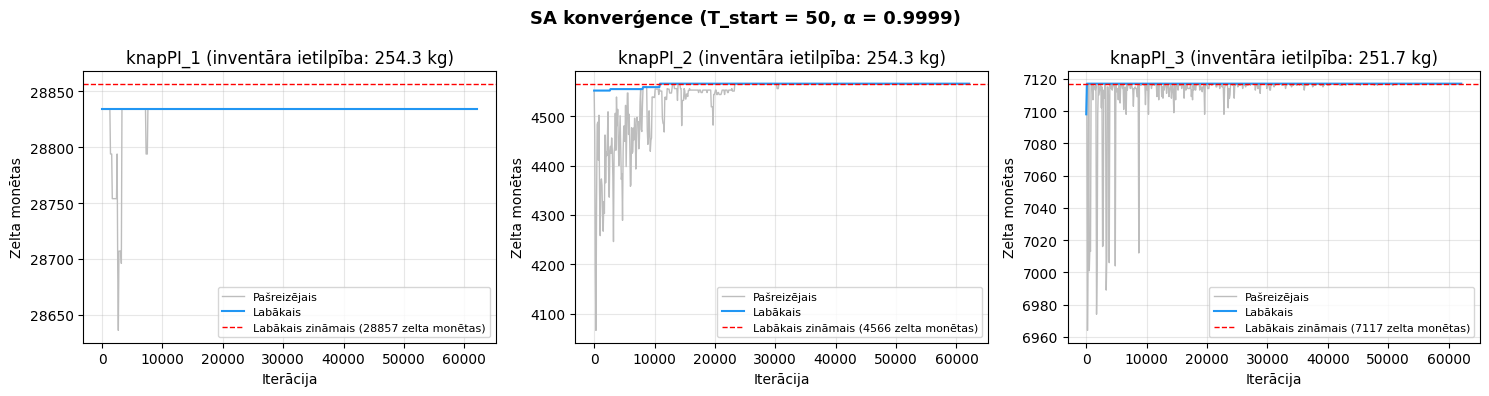

In [26]:
# Inventāra vērtības izmaiņa SA darbības laikā katrā n = 500 datu kopā
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, ds) in zip(axes, datasets.items()):
    random.seed(0)
    r = simulated_annealing(ds['items'], ds['capacity'], T_start=BEST_T_START, alpha=BEST_ALPHA, T_min=T_MIN, track_history=True)

    # Pārbaude: ar to pašu sēklu rezultāts sakrīt ar 7. sadaļas 1. palaišanu
    first_run = next(run for run in results[name] if run['run'] == 1)
    assert r['best_value'] == first_run['value'], '[WARNING] Rezultāts nesakrīt ar 7. sadaļu'

    iters = [h[0] for h in r['history']]
    ax.plot(iters, [h[1] for h in r['history']], color='#BDBDBD', linewidth=1, label='Pašreizējais')
    ax.plot(iters, [h[2] for h in r['history']], color='#2196F3', linewidth=1.5, label='Labākais')
    ax.axhline(ds['optimal'], color='red', linestyle='--', linewidth=1, label=f"Labākais zināmais ({ds['optimal']} zelta monētas)")
    ax.set_title(f"{name} (inventāra ietilpība: {ds['capacity'] / 10:.1f} kg)")
    ax.set_xlabel('Iterācija')
    ax.set_ylabel('Zelta monētas')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle(f'SA konverģence (T_start = {BEST_T_START:g}, α = {BEST_ALPHA:g})', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


**Novērojumi / secinājumi.**

- `knapPI_2` un `knapPI_3` datu kopās grafiks atbilst SA darbības principam – sākumā esošā vērtība stipri svārstās, jo tiek pieņemti par vairākiem simtiem monētu sliktāki inventāri (pelēkā līnija). Temperatūrai krītot, svārstības samazinās, un labākā vērtība sasniedz optimālo – `knapPI_2` pēc ~11 000 iterācijām, `knapPI_3` – gandrīz uzreiz.
- `knapPI_1` datu kopā labākā vērtība nemainās no alkatīgā risinājuma (28 834), un esošā vērtība mainās tikai pirmo ~8000 iterāciju laikā. Lai iegūtu optimālo inventāru, varonim būtu jāieliek priekšmets ar svaru 12,2 kg (667 monētas) un tā vietā jāizņem 2 priekšmeti, kuru kopējais svars ir tieši 10,7 kg (9,1 kg un 1,6 kg). Taču labošanas solis vienmēr vispirms izņem priekšmetu ar vismazāko zelta uz kg attiecību – 18,1 kg priekšmetu, kura vērtība ir 998 monētas, tādēļ šis gājiens noved pie cita, sliktāka inventāra, nevis pie optimālā. Lai nonāktu līdz optimālajam inventāram, algoritmam būtu jāveic vairāki noteikti gājieni pēc kārtas, no kuriem katrs samazina vērtību. Tātad alkatīgais inventārs ir lokālais optimums šim gājienam – no visām 125 palaišanām uz šīs datu kopas 6. sadaļā optimālais risinājums tika atrasts tikai 1 reizi.

### 9.1 Dzesēšanas ātruma ietekme

Lai redzētu, kā `α` ietekmē algoritma darbību, grafikos ir salīdzinātas visas 5 `α` vērtības (`ALPHA_VALUES`) ar izvēlēto `BEST_T_START`. Ātrāka dzesēšana (mazāka `α`) nozīmē mazāk iterāciju, tādēļ algoritms ātrāk beidz darbu, bet tam ir mazāk laika izpētīt dažādus inventārus. Grafikos ir parādīta tikai labākā vērtība (`Best`), un leģendā – galīgā vērtība.


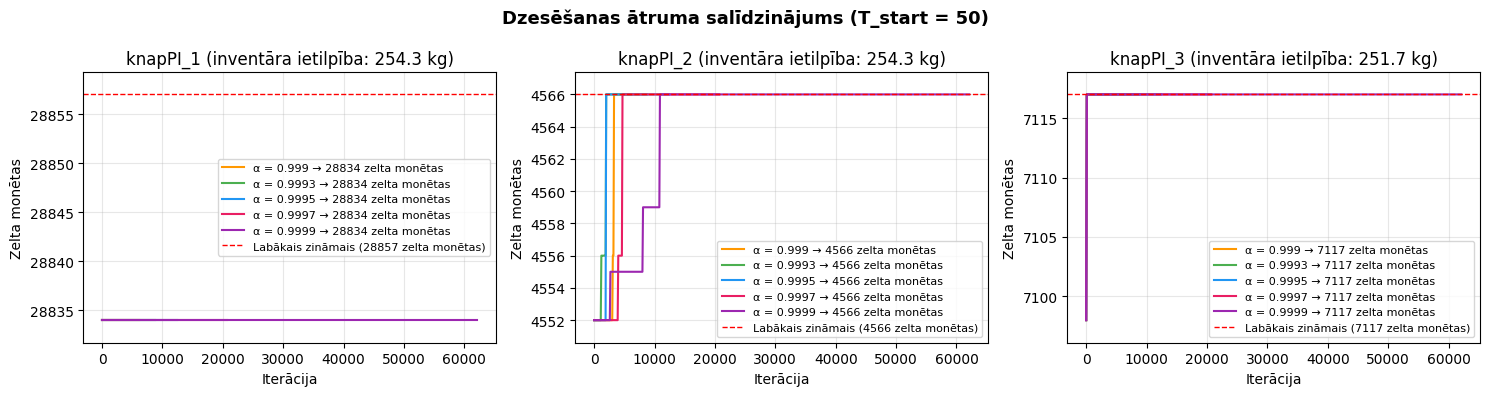

In [28]:
# Labākās vērtības izmaiņa ar dažādām α vērtībām katrā n = 500 datu kopā
alpha_colours = ['#FF9800', '#4CAF50', '#2196F3', '#E91E63', '#9C27B0']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, ds) in zip(axes, datasets.items()):
    lowest = ds['optimal']
    for alpha, colour in zip(ALPHA_VALUES, alpha_colours):
        random.seed(0)
        r = simulated_annealing(ds['items'], ds['capacity'], T_start=BEST_T_START, alpha=alpha, T_min=T_MIN, track_history=True)
        best_values = [h[2] for h in r['history']]
        lowest = min(lowest, min(best_values))
        ax.plot([h[0] for h in r['history']], best_values, color=colour, linewidth=1.5,
                label=f"α = {alpha:g} → {r['best_value']} zelta monētas")

    # y ass robežas pēc datiem un labākās zināmās vērtības (axhline automātiski netiek ņemta vērā)
    margin = max(1, (ds['optimal'] - lowest) * 0.1)
    ax.set_ylim(lowest - margin, ds['optimal'] + margin)

    ax.axhline(ds['optimal'], color='red', linestyle='--', linewidth=1, label=f"Labākais zināmais ({ds['optimal']} zelta monētas)")
    ax.set_title(f"{name} (inventāra ietilpība: {ds['capacity'] / 10:.1f} kg)")
    ax.set_xlabel('Iterācija')
    ax.set_ylabel('Zelta monētas')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle(f'Dzesēšanas ātruma salīdzinājums (T_start = {BEST_T_START:g})', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


**Novērojumi / secinājumi.** 

Visās 3 datu kopās visas 5 `α` vērtības sasniedz vienu un to pašu gala rezultātu. `knapPI_1` – alkatīgo risinājumu (28 834), `knapPI_2` un `knapPI_3` – optimālo. `knapPI_2` datu kopā ātrāka dzesēšana optimālo inventāru atrod pat agrāk (`α ≤ 0,9995` – pēc ~2000–3000, `α = 0,9997` – pēc ~4500, `α = 0,9999` – pēc ~11 000 iterācijām), jo temperatūra ātrāk kļūst zema un algoritms ātrāk pāriet no izpētes uz uzlabošanu.

Tomēr 6. sadaļā lēnākā dzesēšana bija vidēji labākā – galvenokārt `n = 100` un `n = 1000` datu kopās, kur ātrāka dzesēšana biežāk "iestrēgst" lokālajā optimumā. Tātad šīm 3 `n = 500` datu kopām `α` izvēle praktiski neietekmē rezultātu, bet ietekmē izpildes laiku.


## 10. Inventāra vizualizācija

Grafikos katrs punkts ir viens `n = 500` datu kopas priekšmets (svars pret vērtību). Krāsa parāda, vai priekšmets ir ielikts SA labākajā atrastajā inventārā (no 7. sadaļas palaišanām) un/vai optimālajā inventārā:
- zils – abos inventāros;
- oranžs – tikai SA inventārā;
- sarkans – tikai optimālajā inventārā (varonis to atstāja, lai gan vajadzēja paņemt);
- pelēks – nevienā no tiem.

Ja SA inventārs sakrīt ar optimālo, oranžu un sarkanu punktu nav. Tomēr vienai datu kopai var būt vairāki optimālie risinājumi ar vienādu vērtību – tad SA var atrast optimālo vērtību ar citiem priekšmetiem nekā Pisinger datu kopas risinājumā. Tabulā ir apkopots, cik priekšmetu ir katrā inventārā un cik no tiem sakrīt.


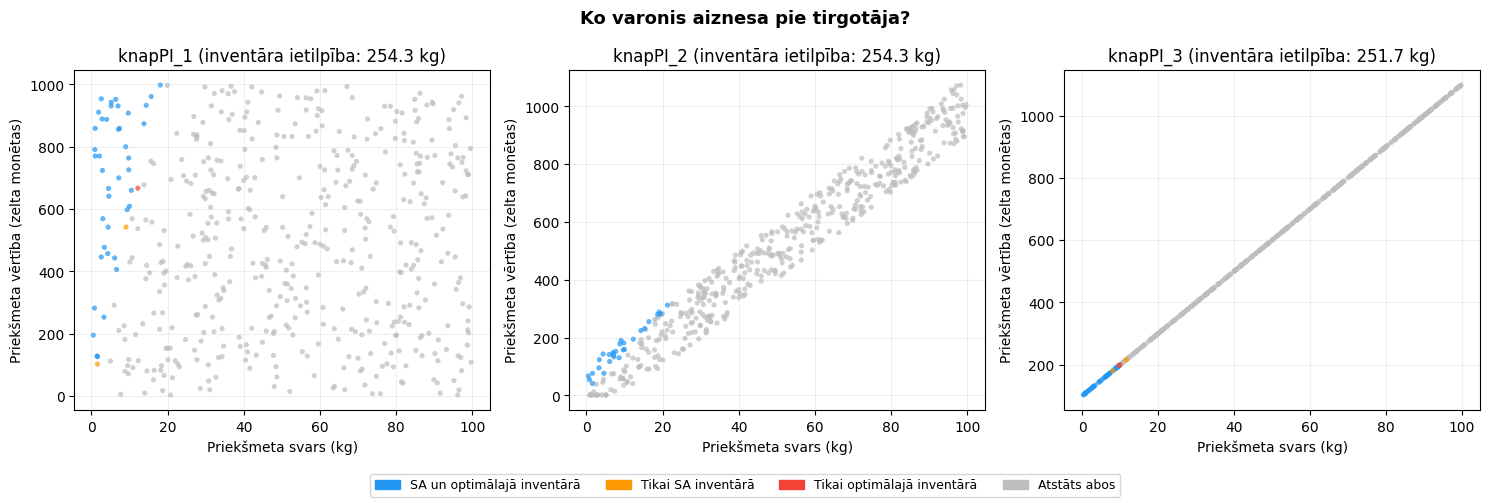

Dataset,Items in SA inventory,Items in optimal inventory,Items in both,SA weight (kg),SA gold,Best known
knapPI_1,43,42,41,252.8 / 254.3,28834,28857
knapPI_2,28,28,28,254.3 / 254.3,4566,4566
knapPI_3,46,46,44,251.7 / 251.7,7117,7117


In [ ]:
# Krāsa pēc tā, vai priekšmets ir (SA inventārā, optimālajā inventārā)
SELECTION_COLOURS = {(1, 1): '#2196F3', (1, 0): '#FF9800', (0, 1): '#F44336', (0, 0): '#BDBDBD'}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
inventory_rows = []
for ax, (name, ds) in zip(axes, datasets.items()):
    items = ds['items']
    best_run = max(results[name], key=lambda r: r['value'])
    sa_sol = best_run['solution']

    # Vispirms pelēkie punkti, lai tie neaizsegtu pārējos
    for key in [(0, 0), (1, 1), (1, 0), (0, 1)]:
        group = [it for i, it in enumerate(items) if (sa_sol[i], it['optimal']) == key]
        ax.scatter([it['weight'] / 10 for it in group], [it['value'] for it in group],
                   color=SELECTION_COLOURS[key], s=14, alpha=0.7, edgecolors='none')
    ax.set_title(f"{name} (inventāra ietilpība: {ds['capacity'] / 10:.1f} kg)")
    ax.set_xlabel('Priekšmeta svars (kg)')
    ax.set_ylabel('Priekšmeta vērtība (zelta monētas)')
    ax.grid(True, alpha=0.2)

    inventory_rows.append({
        'Dataset': name,
        'Items in SA inventory': sum(sa_sol),
        'Items in optimal inventory': sum(it['optimal'] for it in items),
        'Items in both': sum(1 for i, it in enumerate(items) if sa_sol[i] and it['optimal']),
        'SA weight (kg)': f"{best_run['weight_kg']:.1f} / {ds['capacity'] / 10:.1f}",
        'SA gold': best_run['value'],
        'Best known': ds['optimal'],
    })

legend_items = [
    mpatches.Patch(color='#2196F3', label='SA un optimālajā inventārā'),
    mpatches.Patch(color='#FF9800', label='Tikai SA inventārā'),
    mpatches.Patch(color='#F44336', label='Tikai optimālajā inventārā'),
    mpatches.Patch(color='#BDBDBD', label='Atstāts abos'),
]
fig.legend(handles=legend_items, loc='lower center', ncol=4, fontsize=9)
plt.suptitle('Ko varonis aiznesa pie tirgotāja?', fontsize=13, fontweight='bold')
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

pd.DataFrame(inventory_rows).style.hide(axis='index')


**Novērojumi / secinājumi.**

- Izkliedes diagrammas parāda, cik cieši korelēta ir priekšmeta vērtība ar tā svaru:
    - `knapPI_1` – nav korelācijas;
    - `knapPI_2` – vāja korelācija ("vāja" tikai pēc Pisinger dotā nosaukuma, patiesībā, kā redzams, tā ir diezgan korelēta);
    - `knapPI_3` – stipra korelācija.
- `knapPI_1` – 2 oranžie un 1 sarkanais punkts ir tieši 9. sadaļā aprakstītā apmaiņa – optimālajā inventārā ir 12,2 kg priekšmets, kura vietā SA inventārā ir 9,1 kg un 1,6 kg priekšmeti.
- `knapPI_2` – SA inventārs pilnībā sakrīt ar optimālo.
- `knapPI_3` – SA atrada optimālo vērtību (7117) ar citiem priekšmetiem – SA inventārā ir priekšmeti ar svaru 11,6 kg un 8,1 kg (kopā 19,7 kg), bet Pisinger risinājumā – 9,7 kg un 10,0 kg (arī 19,7 kg). Tā kā šajā datu kopā vērtība ir `w + 100`, 2 priekšmetu komplekti ar vienādu kopējo svaru un vienādu priekšmetu skaitu ir vienlīdz vērtīgi.
- Visās datu kopās varonis ņem tikai vieglus priekšmetus (aptuveni līdz 20 kg), jo tiem ir vislabākā zelta uz kg attiecība. `knapPI_1` tie ir viegli un dārgi priekšmeti (grafika augšējais kreisais stūris), bet `knapPI_3` – vienkārši vieglākie priekšmeti.

## 11. Apkopojums un secinājumi

**Uzdevums.**

RPG spēles varonim no `n` priekšmetiem jāizvēlas tādi, lai viņš vienā gājienā pie tirgotāja aiznestu pēc iespējas vērtīgāku inventāru, nepārsniedzot inventāra ietilpību. Tā ir 0/1 mugursomas problēma, kas tika risināta ar Simulated Annealing (SA) algoritmu uz 21 Pisinger datu kopas (3 tipi × 7 izmēri, `n = 100…10000`).

**Pieeja.**

- Sākuma risinājums – alkatīgais risinājums (priekšmeti pēc zelta uz kg attiecības).
- Gājiens – viena priekšmeta maiņa, pārsvara labošana un brīvās vietas aizpildīšana. Bez labošanas un aizpildīšanas 90–94% kaimiņu inventāru pārsniedza ietilpību, un SA uzlaboja sākuma risinājumu tikai `knapPI_3` datu kopā (7.3. sadaļa).
- `T_min = 0,1`, lai beigās netiktu pieņemts pat 1 monētas zaudējums. `T_start` un `α` tika izvēlēti eksperimentā (6. sadaļa), kurā visas 25 kombinācijas tika palaistas 5 reizes uz katras no 21 datu kopām (2625 palaišanas reizes, ~2,5 h).

**Rezultāti.**

- **Parametri (6. sadaļa):** izvēlēti `T_start = 50`, `α = 0,9999`. Ar zemu sākuma temperatūru (`T_start ≤ 10`) algoritms gandrīz nepieņem sliktākus inventārus un iestrēgst lokālajā optimumā neatkarīgi no `α`. Lēnāka dzesēšana kopumā dod labāku rezultātu, taču ir ~10 reizes lēnāka (`α = 0,9999` pret `α = 0,999`).
- **`n = 500` datu kopas (7. sadaļa):** SA atrada optimālo risinājumu 0/5 reizes `knapPI_1`, 5/5 `knapPI_2` un 5/5 `knapPI_3` datu kopās; vidējā atšķirība no optimālā – 0,027%. Salīdzinājumā ar alkatīgo risinājumu SA uzlaboja inventāru par 14 (`knapPI_2`) un 19 (`knapPI_3`) zelta monētām, bet `knapPI_1` – neuzlaboja, jo alkatīgais inventārs ir lokālais optimums izmantotajam gājienam (9. sadaļa).
- **Retums (7.2. sadaļa):** `knapPI_1` un `knapPI_2` datu kopās optimālajā inventārā ir vairāk retāku priekšmetu (no `Legendary` – 23,5%, no `Common` – tikai 1-4%), jo retāks priekšmets ir dārgāks par līdzīga svara priekšmetiem. `knapPI_3` datu kopā ir pretēji – dārgāks priekšmets ir arī smagāks, tādēļ optimālajā inventārā visbiežāk ir `Common` priekšmeti.
- **Dažādi izmēri (8. sadaļa):** visās datu kopās vidējā atšķirība no optimālā nepārsniedz 0,11%, un `knapPI_3` datu kopās optimālais risinājums tiek atrasts vienmēr. Lielākās datu kopās optimums tiek atrasts retāk, taču arī alkatīgais risinājums tur ir ļoti tuvu optimālajam. Iterāciju skaits nav atkarīgs no `n`, bet izpildes laiks pieaug no ~0,4-0,9 s (`n ≤ 200`) līdz ~26-51 s (`n = 10000`), jo gājiens pārskata priekšmetu sarakstus.

**Kopsavilkums.**

SA ar labošanas un aizpildīšanas gājienu visās 21 datu kopās atrod inventāru, kas no optimālā atpaliek vidēji ne vairāk kā par 0,11%, un 14 no 21 datu kopām vismaz vienā palaišanā atrod optimālo inventāru. Tātad **varonis praktiski vienmēr aiznes pie tirgotāja gandrīz maksimāli iespējamo zelta daudzumu**. Galvenais ierobežojums ir labošanas solis, jo tas vienmēr izņem priekšmetu ar vismazāko zelta uz kg attiecību, tādēļ dažos gadījumos (piem., `knapPI_1_500`) algoritms nevar nonākt līdz optimālajam inventāram, kam ir vajadzīga cita priekšmetu apmaiņa.
